# Συνεργάζεται το Πανεπιστήμιό σου με το Ισραήλ σε έργα του Horizon Europe?

Συλλέξαμε δεδομένα από την επίσημη ευρωπαϊκή πλατφόρμα του [Horizon Europe (2021-2027)](https://data.europa.eu/data/datasets/cordis-eu-research-projects-under-horizon-europe-2021-2027?locale=en).

Κατά τη δημοσίευση του ρεπορτάζ μας [«Οκτώ ελληνικά πανεπιστήμια πρόθυμοι εταίροι του ισραηλινού κράτους»](https://www.reportersunited.gr/19091/horizon-europe-panepistimia-israel/) σχετικά με τις συνεργασίες ευρωπαϊκών πανεπιστημίων με το ισραηλινό κράτος και με ισραηλινές εταιρείες και πανεπιστήμια που έχουν συνδέσεις με τον ισραηλινό στρατό, συλλέξαμε δεδομένα μέχρι τον Μάιο του 2026. Τα δεδομένα συλλέχθηκαν σε μορφή json και δημιουργήθηκε μια βάση δεδομένων που περιέχει όλα τα υπογεγραμμένα έργα (με τη σήμανση signed) στα οποία συμμετέχει τουλάχιστον ένα πανεπιστήμιο ή ακαδημαϊκό ίδρυμα της ΕΕ (περιγράφεται ως HES στα δεδομένα του Horizon) και ένας ισραηλινός φορέας. Κατά την ανανέωση των δεδομένων τον Οκτώβριο του 2026 για την δημιουργία της [διαδραστικής εφαρμογής](https://data.reportersunited.gr/horizon-universities-israel/el/), όπου συλλέξαμε τα ίδια δεδομένα σε μορφή xlsx, παρουσιάζονται κάποιες διαφορές που οφείλονται σε αναθεωρήσεις των έργων και αφορούν τόσο τον τερματισμό κάποιων έργων που μέχρι τον Μάιο φαίνονταν ενεργά, όσο και τα ποσά χρηματοδότησης των συμμετεχόντων από την ΕΕ και τον ρόλο τους στα έργα.

Παρακάτω παρουσιάζουμε τη μεθοδολογία συλλογής των έργων και τη δημιουργία μιας καθαρής βάσης δεδομένων προς ανάλυση.

- Συλλογή δεδομένων από το Reporters United: 27.10.2026
- Ανανέωση δεδομένων από την ΕΕ: 15.10.2026
 
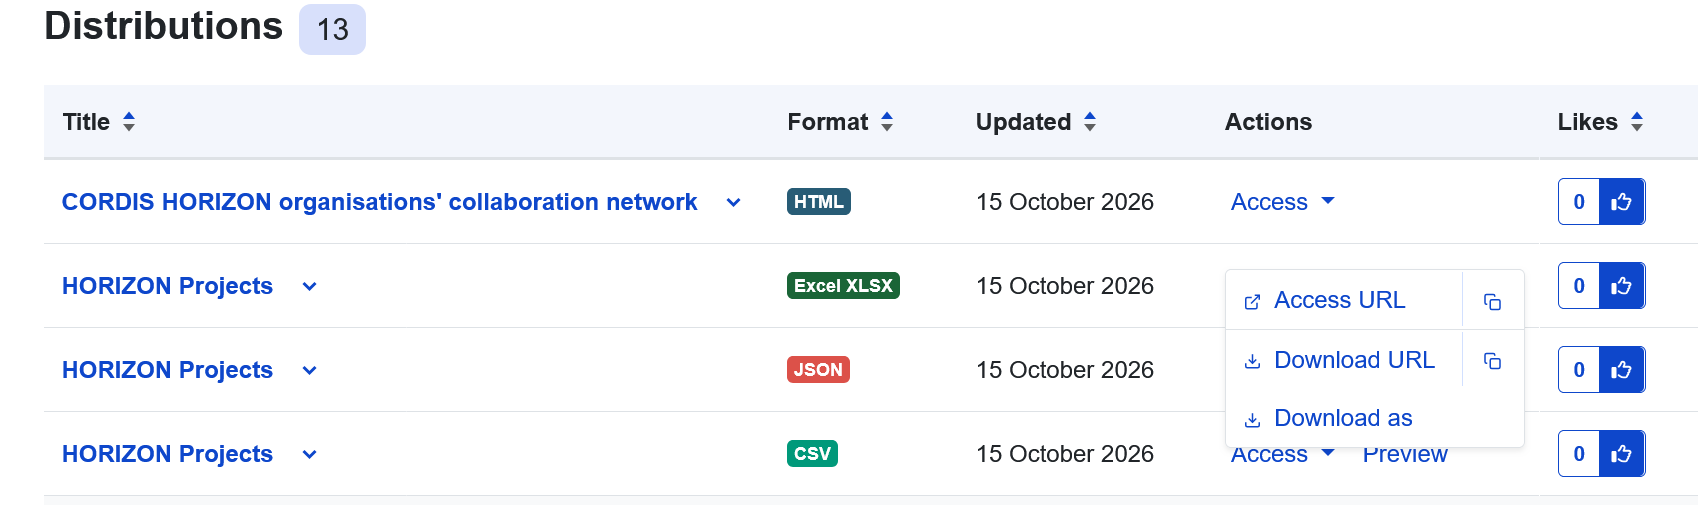


------------

Όταν κατεβάζουμε τα δεδομένα σε μορφή xlsx καταλήγουμε με έναν φάκελο που περιέχει διάφορα σύνολα δεδομένων. Αυτά πρέπει να ενωθούν για να έχουμε την πλήρη βάση δεδομένων μας πάνω στην οποία θα δουλέψουμε. 

## Πρώτα ανοίγουμε το ντάτασετ με τα έργα (projects)

In [1]:
import pandas as pd
import numpy as np
import re

In [2]:
projects = pd.read_excel("cordis-HORIZONprojects-xlsx-update/project.xlsx")
projects.info()

C:\Users\kwnst\AppData\Local\Programs\Python\Python314\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


<class 'pandas.DataFrame'>
RangeIndex: 23954 entries, 0 to 23953
Data columns (total 22 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id                  23954 non-null  int64         
 1   acronym             23954 non-null  str           
 2   status              23954 non-null  str           
 3   title               23954 non-null  str           
 4   startDate           23954 non-null  str           
 5   endDate             23954 non-null  str           
 6   totalCost           23954 non-null  float64       
 7   ecMaxContribution   23954 non-null  float64       
 8   topics              23954 non-null  str           
 9   ecSignatureDate     23954 non-null  str           
 10  frameworkProgramme  23954 non-null  str           
 11  masterCall          23954 non-null  str           
 12  subCall             23954 non-null  str           
 13  fundingScheme       23954 non-null  str           
 14  n

## Έπειτα το ντάτασετ που περιέχει περισσότερες πληροφορίες σχετικά με τα έργα όπως τη θεματική που ανήκουν στο Horizon.

In [3]:
topics = pd.read_excel("cordis-HORIZONprojects-xlsx-update/topics.xlsx")
topics.info()

C:\Users\kwnst\AppData\Local\Programs\Python\Python314\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


<class 'pandas.DataFrame'>
RangeIndex: 23954 entries, 0 to 23953
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   topic      23954 non-null  str  
 1   title      23954 non-null  str  
 2   projectID  23954 non-null  int64
dtypes: int64(1), str(2)
memory usage: 561.6 KB


## Ενώνουμε τα δύο ντάτασετ με βάση το ID του πρότζεκτ.

In [4]:
projects_with_topic_title = projects.merge(topics, left_on="id", right_on="projectID", how="inner")
projects_with_topic_title

,id,acronym,status,title_x,startDate,endDate,totalCost,ecMaxContribution,topics,ecSignatureDate,...,objective,contentUpdateDate,rcn,grantDoi,keywords,Human-validated,legalBasis,topic,title_y,projectID
0,101069359,SolDAC,SIGNED,Full spectrum SOLar Direct Air Capture & conve...,2022-09-01,2025-08-31,2073781.25,2073781.25,HORIZON-CL5-2021-D2-01-11,2022-05-12,...,Ethylene is the chemical industry’s primary bu...,2026-03-27 15:10:23,237915,10.3030/101069359,"zero-carbon, solar energy, air mining, Negativ...",True,HORIZON.2.5,HORIZON-CL5-2021-D2-01-11,Direct atmospheric carbon capture and conversion,101069359
1,101069357,Photo2Fuel,SIGNED,Artificial PHOTOsynthesis to produce FUELs and...,2022-09-01,2025-08-31,2493171.25,2493171.00,HORIZON-CL5-2021-D2-01-08,2022-05-18,...,The Photo2Fuel project will develop a breakthr...,2026-02-12 19:21:26,237916,10.3030/101069357,solar energy; bacteria; archaea; solar fuels; ...,True,HORIZON.2.5,HORIZON-CL5-2021-D2-01-08,Emerging technologies for a climate neutral Eu...,101069357
2,101069586,BOLSTER,SIGNED,Bridging Organizations and marginalized commun...,2022-09-01,2025-08-31,3792955.00,3792955.00,HORIZON-CL5-2021-D2-01-12,2022-06-10,...,No European should be put at a disadvantaged b...,2026-08-25 11:12:41,237917,10.3030/101069586,Transition strategies; Participation; Marginal...,True,HORIZON.2.5,HORIZON-CL5-2021-D2-01-12,Fostering a just transition in Europe,101069586
3,101069604,GREENET,SIGNED,NCPS NETwork for the GREEN transition in clima...,2022-07-01,2027-12-31,3250901.25,3250901.25,HORIZON-CL5-2021-D2-01-15,2022-06-09,...,The overall aim of GREENET is to improve the p...,2026-06-22 12:35:17,237918,10.3030/101069604,"Competence development, Capacity building, CL5...",NaN,HORIZON.2.5,HORIZON-CL5-2021-D2-01-15,Fostering cooperation between Horizon Europe c...,101069604
4,101069529,SSH CENTRE,SIGNED,"Social Sciences and Humanities for Climate, En...",2022-09-01,2026-02-28,2305696.25,2305696.00,HORIZON-CL5-2021-D2-01-13,2022-05-20,...,"The Social Sciences & Humanities for Climate, ...",2026-04-15 15:27:43,237919,10.3030/101069529,Transitions; Transdisciplinary; Epistemic cult...,True,HORIZON.2.5,HORIZON-CL5-2021-D2-01-13,Strengthening Social Sciences and Humanities (...,101069529
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23949,101334514,CLIMATE-HUBS,SIGNED,Connecting Climate Tech Innovation Hubs for Us...,2027-02-01,2029-01-31,0.00,1995951.00,HORIZON-WIDERA-2026-06-ERA-04,2026-09-30,...,CLIMATE-HUBS strengthens Europe’s knowledge va...,2026-10-02 13:41:35,293255,10.3030/101334514,"climate tech, academic startups, knowledge val...",NaN,HORIZON.4.2,HORIZON-WIDERA-2026-06-ERA-04,Pillar II: Piloting innovative approaches to s...,101334514
23950,101315030,HKM1800,SIGNED,Empowering EU Logistics and Manufacturing with...,2026-10-01,2028-09-30,0.00,2498422.00,HORIZON-EIC-2026-ACCELERATOR-02-OPEN,2026-09-28,...,"Cognibotics, a deep-tech Swedish company, pion...",2026-10-02 13:41:35,293256,NaN,NaN,NaN,HORIZON.3.1,HORIZON-EIC-2026-ACCELERATOR-02-OPEN,Accelerator Open,101315030
23951,101331786,SIFFRA,SIGNED,Scalable Interference-Free Radar technology fo...,2026-11-01,2028-10-31,0.00,2495062.50,HORIZON-EIC-2026-ACCELERATOR-02-OPEN,2026-09-28,...,Radar Reticence develops the world’s first int...,2026-10-02 13:41:35,293257,NaN,Radar Interference Mitigation; Interference-fr...,NaN,HORIZON.3.1,HORIZON-EIC-2026-ACCELERATOR-02-OPEN,Accelerator Open,101331786
23952,101301321,UBACT,SIGNED,Principles of UFMylation-driven antibacterial ...,2027-05-01,2032-04-30,2296585.48,1898233.00,ERC-2026-STG,2026-09-30,...,Shigella is a Gram-negative bacterium that cau...,2026-10-02 13:41:35,293258,10.3030/101301321,"Shigella, ubiquitin-like systems, UFMylation, ...",NaN,HORIZON.1.1,ERC-2026-STG,ERC STARTING GRANTS,101301321


Μετονομάζουμε τις στήλες που είναι ίδιες

In [5]:
projects_with_topic_title = projects_with_topic_title.rename(
    columns={"title_y": "topic_title",
            "title_x": "project_title"}
)
projects_with_topic_title

,id,acronym,status,project_title,startDate,endDate,totalCost,ecMaxContribution,topics,ecSignatureDate,...,objective,contentUpdateDate,rcn,grantDoi,keywords,Human-validated,legalBasis,topic,topic_title,projectID
0,101069359,SolDAC,SIGNED,Full spectrum SOLar Direct Air Capture & conve...,2022-09-01,2025-08-31,2073781.25,2073781.25,HORIZON-CL5-2021-D2-01-11,2022-05-12,...,Ethylene is the chemical industry’s primary bu...,2026-03-27 15:10:23,237915,10.3030/101069359,"zero-carbon, solar energy, air mining, Negativ...",True,HORIZON.2.5,HORIZON-CL5-2021-D2-01-11,Direct atmospheric carbon capture and conversion,101069359
1,101069357,Photo2Fuel,SIGNED,Artificial PHOTOsynthesis to produce FUELs and...,2022-09-01,2025-08-31,2493171.25,2493171.00,HORIZON-CL5-2021-D2-01-08,2022-05-18,...,The Photo2Fuel project will develop a breakthr...,2026-02-12 19:21:26,237916,10.3030/101069357,solar energy; bacteria; archaea; solar fuels; ...,True,HORIZON.2.5,HORIZON-CL5-2021-D2-01-08,Emerging technologies for a climate neutral Eu...,101069357
2,101069586,BOLSTER,SIGNED,Bridging Organizations and marginalized commun...,2022-09-01,2025-08-31,3792955.00,3792955.00,HORIZON-CL5-2021-D2-01-12,2022-06-10,...,No European should be put at a disadvantaged b...,2026-08-25 11:12:41,237917,10.3030/101069586,Transition strategies; Participation; Marginal...,True,HORIZON.2.5,HORIZON-CL5-2021-D2-01-12,Fostering a just transition in Europe,101069586
3,101069604,GREENET,SIGNED,NCPS NETwork for the GREEN transition in clima...,2022-07-01,2027-12-31,3250901.25,3250901.25,HORIZON-CL5-2021-D2-01-15,2022-06-09,...,The overall aim of GREENET is to improve the p...,2026-06-22 12:35:17,237918,10.3030/101069604,"Competence development, Capacity building, CL5...",NaN,HORIZON.2.5,HORIZON-CL5-2021-D2-01-15,Fostering cooperation between Horizon Europe c...,101069604
4,101069529,SSH CENTRE,SIGNED,"Social Sciences and Humanities for Climate, En...",2022-09-01,2026-02-28,2305696.25,2305696.00,HORIZON-CL5-2021-D2-01-13,2022-05-20,...,"The Social Sciences & Humanities for Climate, ...",2026-04-15 15:27:43,237919,10.3030/101069529,Transitions; Transdisciplinary; Epistemic cult...,True,HORIZON.2.5,HORIZON-CL5-2021-D2-01-13,Strengthening Social Sciences and Humanities (...,101069529
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23949,101334514,CLIMATE-HUBS,SIGNED,Connecting Climate Tech Innovation Hubs for Us...,2027-02-01,2029-01-31,0.00,1995951.00,HORIZON-WIDERA-2026-06-ERA-04,2026-09-30,...,CLIMATE-HUBS strengthens Europe’s knowledge va...,2026-10-02 13:41:35,293255,10.3030/101334514,"climate tech, academic startups, knowledge val...",NaN,HORIZON.4.2,HORIZON-WIDERA-2026-06-ERA-04,Pillar II: Piloting innovative approaches to s...,101334514
23950,101315030,HKM1800,SIGNED,Empowering EU Logistics and Manufacturing with...,2026-10-01,2028-09-30,0.00,2498422.00,HORIZON-EIC-2026-ACCELERATOR-02-OPEN,2026-09-28,...,"Cognibotics, a deep-tech Swedish company, pion...",2026-10-02 13:41:35,293256,NaN,NaN,NaN,HORIZON.3.1,HORIZON-EIC-2026-ACCELERATOR-02-OPEN,Accelerator Open,101315030
23951,101331786,SIFFRA,SIGNED,Scalable Interference-Free Radar technology fo...,2026-11-01,2028-10-31,0.00,2495062.50,HORIZON-EIC-2026-ACCELERATOR-02-OPEN,2026-09-28,...,Radar Reticence develops the world’s first int...,2026-10-02 13:41:35,293257,NaN,Radar Interference Mitigation; Interference-fr...,NaN,HORIZON.3.1,HORIZON-EIC-2026-ACCELERATOR-02-OPEN,Accelerator Open,101331786
23952,101301321,UBACT,SIGNED,Principles of UFMylation-driven antibacterial ...,2027-05-01,2032-04-30,2296585.48,1898233.00,ERC-2026-STG,2026-09-30,...,Shigella is a Gram-negative bacterium that cau...,2026-10-02 13:41:35,293258,10.3030/101301321,"Shigella, ubiquitin-like systems, UFMylation, ...",NaN,HORIZON.1.1,ERC-2026-STG,ERC STARTING GRANTS,101301321


## Διαβάζουμε το εξέλ που περιέχει διάφορα σχετικά λινκς ανά έργο (project)

In [6]:
link = pd.read_excel("cordis-HORIZONprojects-xlsx-update/webLink.xlsx")

link.drop(columns=["id", "availableLanguages", "status", "archivedDate", "type", "source", "represents"], inplace=True)

collapsed_links = (
    link.groupby("projectID")["physUrl"]
      .apply(lambda x: ", ".join(x))
      .reset_index()
)

collapsed_links

C:\Users\kwnst\AppData\Local\Programs\Python\Python314\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,projectID,physUrl
0,101039048,https://ec.europa.eu/research/participants/doc...
1,101039060,https://ec.europa.eu/research/participants/doc...
2,101039103,https://ec.europa.eu/research/participants/doc...
3,101039110,https://ec.europa.eu/research/participants/doc...
4,101039152,https://ec.europa.eu/research/participants/doc...
...,...,...
11787,190195324,https://ec.europa.eu/research/participants/doc...
11788,190195702,https://ec.europa.eu/research/participants/doc...
11789,190196128,https://ec.europa.eu/research/participants/doc...
11790,190198323,https://ec.europa.eu/research/participants/doc...


In [7]:
collapsed_links.rename(columns={"physUrl": "project_docs_urls"}, inplace=True)
collapsed_links

,projectID,project_docs_urls
0,101039048,https://ec.europa.eu/research/participants/doc...
1,101039060,https://ec.europa.eu/research/participants/doc...
2,101039103,https://ec.europa.eu/research/participants/doc...
3,101039110,https://ec.europa.eu/research/participants/doc...
4,101039152,https://ec.europa.eu/research/participants/doc...
...,...,...
11787,190195324,https://ec.europa.eu/research/participants/doc...
11788,190195702,https://ec.europa.eu/research/participants/doc...
11789,190196128,https://ec.europa.eu/research/participants/doc...
11790,190198323,https://ec.europa.eu/research/participants/doc...


Προσθέτουμε τα λινκς στο προηγούμενο ντάτασετ

In [8]:
projects_with_topic_title_link = projects_with_topic_title.merge(collapsed_links, left_on="id", right_on="projectID", how="outer")
projects_with_topic_title_link

,id,acronym,status,project_title,startDate,endDate,totalCost,ecMaxContribution,topics,ecSignatureDate,...,rcn,grantDoi,keywords,Human-validated,legalBasis,topic,topic_title,projectID_x,projectID_y,project_docs_urls
0,101039048,GanESS,SIGNED,Gaseous detectors for neutrino physics at the ...,2022-02-01,2028-01-31,1496205.00,1496205.0,ERC-2021-STG,2022-01-25,...,237999,10.3030/101039048,"neutrino, gas-detectors, coherent-scattering",True,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,101039048,101039048.0,https://ec.europa.eu/research/participants/doc...
1,101039060,PalaeOrigins,SIGNED,Tracing the Epipalaeolithic origins of plant m...,2023-09-01,2028-08-31,1499150.00,1499150.0,ERC-2021-STG,2022-07-23,...,240497,10.3030/101039060,"Epipalaeolithic, Archaeobotany, Human Niche Co...",True,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,101039060,101039060.0,https://ec.europa.eu/research/participants/doc...
2,101039066,ForestFuture,SIGNED,Climate change impacts on trees reproduction a...,2023-01-01,2027-12-31,1482050.00,1482050.0,ERC-2021-STG,2022-05-05,...,237996,10.3030/101039066,NaN,True,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,101039066,NaN,NaN
3,101039090,TOPS,SIGNED,Machine-Assisted Teaching for Open-Ended Probl...,2022-04-01,2027-03-31,1495000.00,1495000.0,ERC-2021-STG,2022-02-14,...,237993,10.3030/101039090,"educational technology, artificial intelligenc...",True,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,101039090,NaN,NaN
4,101039098,QUANTWIST,SIGNED,Enhanced quantum resilience through twists,2023-03-01,2028-02-29,1458688.00,1458688.0,ERC-2021-STG,2022-10-19,...,242665,10.3030/101039098,"Topology, helices, skyrmions, quantum informat...",False,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,101039098,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23949,190198819,FKBP,SIGNED,Fimuskraft Biogas Plant (FKBP): a revolutionar...,2022-05-01,2024-04-30,3432125.00,2402487.0,HORIZON-EIC-2021-ACCELERATORCHALLENGES-01-02,2022-09-14,...,242077,10.3030/190198819,"food and beverage,sustainability,biorefinery,c...",False,HORIZON.3.1,HORIZON-EIC-2021-ACCELERATORCHALLENGES-01-02,Green Deal innovations for the Economic Recovery,190198819,NaN,NaN
23950,190199097,3D Bonding,CLOSED,New industrial process for footwear manufactur...,2022-08-01,2024-07-31,1843318.54,1290322.0,HORIZON-EIC-2021-ACCELERATOROPEN-01,2022-07-27,...,240698,10.3030/190199097,"Automation and control systems,Manufacturing a...",False,HORIZON.3.1,HORIZON-EIC-2021-ACCELERATOROPEN-01,EIC Accelerator Open 2021,190199097,190199097.0,https://ec.europa.eu/research/participants/doc...
23951,190199127,HCAI4ALL,CLOSED,Human-Centric AI platform for heALth and Life ...,2023-01-01,2024-12-31,3564427.50,2495099.0,HORIZON-EIC-2022-ACCELERATOROPEN-01,2022-11-16,...,243089,10.3030/190199127,"Drugs,Visualization and natural language proce...",False,HORIZON.3.1,HORIZON-EIC-2022-ACCELERATOROPEN-01,EIC Accelerator Open,190199127,NaN,NaN
23952,190199469,NANOWOUND,SIGNED,Antibacterial wound dressing based on advanced...,2023-04-01,2026-03-31,3432500.00,2402750.0,HORIZON-EIC-2022-ACCELERATOROPEN-01,2022-12-14,...,243876,10.3030/190199469,"Antibiotic resistance,Burn wounds,Diabetic foo...",False,HORIZON.3.1,HORIZON-EIC-2022-ACCELERATOROPEN-01,EIC Accelerator Open,190199469,NaN,NaN


In [9]:
projects_with_topic_title_link.drop(columns=["projectID_y", "projectID_x"], inplace=True)

## Διαβάζουμε το εξέλ που περιέχει πληροφορίες όπως σε ποιον τομέα ανήκει το κάθε έργο 

In [10]:
policy_ranking = pd.read_excel("cordis-HORIZONprojects-xlsx-update/policyPriorities.xlsx")
policy_ranking

C:\Users\kwnst\AppData\Local\Programs\Python\Python314\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,ai,biodiversity,cleanAir,climate,digitalAgenda,projectID
0,NaN,NaN,NaN,NaN,0.0,101069359
1,NaN,NaN,0.0,NaN,NaN,101069359
2,0.0,NaN,NaN,NaN,NaN,101069359
3,NaN,NaN,NaN,100.0,NaN,101069359
4,NaN,0.0,NaN,NaN,NaN,101069359
...,...,...,...,...,...,...
114752,NaN,NaN,NaN,NaN,100.0,101331836
114753,NaN,NaN,0.0,NaN,NaN,101331836
114754,40.0,NaN,NaN,NaN,NaN,101331836
114755,NaN,NaN,NaN,0.0,NaN,101331836


Μετονομάζουμε για κατανόηση τις στήλες

In [11]:
policy_ranking.rename(columns={"ai": "policy_ranking_AI", 
                               "biodiversity": "policy_ranking_BIODIVERSITY",
                               "cleanAir": "policy_ranking_CLEAN_AIR",
                               "climate": "policy_ranking_CLIMATE",
                               "digitalAgenda": "policy_ranking_DIGITAL_AGENDA"},
                     inplace=True)
policy_ranking

,policy_ranking_AI,policy_ranking_BIODIVERSITY,policy_ranking_CLEAN_AIR,policy_ranking_CLIMATE,policy_ranking_DIGITAL_AGENDA,projectID
0,NaN,NaN,NaN,NaN,0.0,101069359
1,NaN,NaN,0.0,NaN,NaN,101069359
2,0.0,NaN,NaN,NaN,NaN,101069359
3,NaN,NaN,NaN,100.0,NaN,101069359
4,NaN,0.0,NaN,NaN,NaN,101069359
...,...,...,...,...,...,...
114752,NaN,NaN,NaN,NaN,100.0,101331836
114753,NaN,NaN,0.0,NaN,NaN,101331836
114754,40.0,NaN,NaN,NaN,NaN,101331836
114755,NaN,NaN,NaN,0.0,NaN,101331836


Καθαρίζουμε το ντάτασετ ώστε κάθε γραμμή να είναι ένα έργο 

In [12]:
collapsed_policy_ranking = (
    policy_ranking
    .groupby("projectID", as_index=False)
    .max()
)

collapsed_policy_ranking

,projectID,policy_ranking_AI,policy_ranking_BIODIVERSITY,policy_ranking_CLEAN_AIR,policy_ranking_CLIMATE,policy_ranking_DIGITAL_AGENDA
0,101039048,0.0,0.0,0.0,0.0,0.0
1,101039060,0.0,0.0,0.0,0.0,0.0
2,101039066,0.0,0.0,0.0,100.0,0.0
3,101039090,0.0,0.0,0.0,0.0,0.0
4,101039098,0.0,0.0,0.0,0.0,40.0
...,...,...,...,...,...,...
23087,190198819,0.0,40.0,40.0,40.0,0.0
23088,190199097,0.0,0.0,0.0,0.0,0.0
23089,190199127,100.0,0.0,0.0,0.0,40.0
23090,190199469,0.0,0.0,0.0,0.0,0.0


Ενώνουμε με το προηγούμενο ντάτασετ

In [13]:
projects_with_topic_title_link_policies = projects_with_topic_title_link.merge(collapsed_policy_ranking, left_on="id", right_on="projectID", how="outer")
projects_with_topic_title_link_policies

,id,acronym,status,project_title,startDate,endDate,totalCost,ecMaxContribution,topics,ecSignatureDate,...,legalBasis,topic,topic_title,project_docs_urls,projectID,policy_ranking_AI,policy_ranking_BIODIVERSITY,policy_ranking_CLEAN_AIR,policy_ranking_CLIMATE,policy_ranking_DIGITAL_AGENDA
0,101039048,GanESS,SIGNED,Gaseous detectors for neutrino physics at the ...,2022-02-01,2028-01-31,1496205.00,1496205.0,ERC-2021-STG,2022-01-25,...,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,https://ec.europa.eu/research/participants/doc...,101039048.0,0.0,0.0,0.0,0.0,0.0
1,101039060,PalaeOrigins,SIGNED,Tracing the Epipalaeolithic origins of plant m...,2023-09-01,2028-08-31,1499150.00,1499150.0,ERC-2021-STG,2022-07-23,...,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,https://ec.europa.eu/research/participants/doc...,101039060.0,0.0,0.0,0.0,0.0,0.0
2,101039066,ForestFuture,SIGNED,Climate change impacts on trees reproduction a...,2023-01-01,2027-12-31,1482050.00,1482050.0,ERC-2021-STG,2022-05-05,...,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,NaN,101039066.0,0.0,0.0,0.0,100.0,0.0
3,101039090,TOPS,SIGNED,Machine-Assisted Teaching for Open-Ended Probl...,2022-04-01,2027-03-31,1495000.00,1495000.0,ERC-2021-STG,2022-02-14,...,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,NaN,101039090.0,0.0,0.0,0.0,0.0,0.0
4,101039098,QUANTWIST,SIGNED,Enhanced quantum resilience through twists,2023-03-01,2028-02-29,1458688.00,1458688.0,ERC-2021-STG,2022-10-19,...,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,NaN,101039098.0,0.0,0.0,0.0,0.0,40.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23949,190198819,FKBP,SIGNED,Fimuskraft Biogas Plant (FKBP): a revolutionar...,2022-05-01,2024-04-30,3432125.00,2402487.0,HORIZON-EIC-2021-ACCELERATORCHALLENGES-01-02,2022-09-14,...,HORIZON.3.1,HORIZON-EIC-2021-ACCELERATORCHALLENGES-01-02,Green Deal innovations for the Economic Recovery,NaN,190198819.0,0.0,40.0,40.0,40.0,0.0
23950,190199097,3D Bonding,CLOSED,New industrial process for footwear manufactur...,2022-08-01,2024-07-31,1843318.54,1290322.0,HORIZON-EIC-2021-ACCELERATOROPEN-01,2022-07-27,...,HORIZON.3.1,HORIZON-EIC-2021-ACCELERATOROPEN-01,EIC Accelerator Open 2021,https://ec.europa.eu/research/participants/doc...,190199097.0,0.0,0.0,0.0,0.0,0.0
23951,190199127,HCAI4ALL,CLOSED,Human-Centric AI platform for heALth and Life ...,2023-01-01,2024-12-31,3564427.50,2495099.0,HORIZON-EIC-2022-ACCELERATOROPEN-01,2022-11-16,...,HORIZON.3.1,HORIZON-EIC-2022-ACCELERATOROPEN-01,EIC Accelerator Open,NaN,190199127.0,100.0,0.0,0.0,0.0,40.0
23952,190199469,NANOWOUND,SIGNED,Antibacterial wound dressing based on advanced...,2023-04-01,2026-03-31,3432500.00,2402750.0,HORIZON-EIC-2022-ACCELERATOROPEN-01,2022-12-14,...,HORIZON.3.1,HORIZON-EIC-2022-ACCELERATOROPEN-01,EIC Accelerator Open,NaN,190199469.0,0.0,0.0,0.0,0.0,0.0


In [14]:
projects_with_topic_title_link_policies.drop(columns=["projectID"], inplace=True)

Η ΕΕ βαθμολογεί τις δράσεις και τους προϋπολογισμούς τους ανάλογα με το πόσο συμβάλλουν, για παράδειγμα, στην προστασία του κλίματος: 100% για μεγάλη συμβολή, 40% για σημαντική συμβολή και 0% για μικρή ή μηδενική συμβολή.Η ΕΕ βαθμολογεί τις δράσεις και τους προϋπολογισμούς τους ανάλογα με το πόσο συμβάλλουν, για παράδειγμα, στην προστασία του κλίματος: 100% για μεγάλη συμβολή, 40% για σημαντική συμβολή και 0% για μικρή ή μηδενική συμβολή.
Για μεγαλύτερη κατανόηση αντικαθιστούμε τους αριθμούς αντίστοιχα.

In [15]:
mapping = {
    0.0: "marginal impact",
    40.0: "significant impact",
    100.0: "major impact"
}

cols = [
    "policy_ranking_AI",
    "policy_ranking_BIODIVERSITY",
    "policy_ranking_CLEAN_AIR",
    "policy_ranking_CLIMATE",
    "policy_ranking_DIGITAL_AGENDA",
]

projects_with_topic_title_link_policies[cols] = projects_with_topic_title_link_policies[cols].replace(mapping)
projects_with_topic_title_link_policies

,id,acronym,status,project_title,startDate,endDate,totalCost,ecMaxContribution,topics,ecSignatureDate,...,Human-validated,legalBasis,topic,topic_title,project_docs_urls,policy_ranking_AI,policy_ranking_BIODIVERSITY,policy_ranking_CLEAN_AIR,policy_ranking_CLIMATE,policy_ranking_DIGITAL_AGENDA
0,101039048,GanESS,SIGNED,Gaseous detectors for neutrino physics at the ...,2022-02-01,2028-01-31,1496205.00,1496205.0,ERC-2021-STG,2022-01-25,...,True,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,https://ec.europa.eu/research/participants/doc...,marginal impact,marginal impact,marginal impact,marginal impact,marginal impact
1,101039060,PalaeOrigins,SIGNED,Tracing the Epipalaeolithic origins of plant m...,2023-09-01,2028-08-31,1499150.00,1499150.0,ERC-2021-STG,2022-07-23,...,True,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,https://ec.europa.eu/research/participants/doc...,marginal impact,marginal impact,marginal impact,marginal impact,marginal impact
2,101039066,ForestFuture,SIGNED,Climate change impacts on trees reproduction a...,2023-01-01,2027-12-31,1482050.00,1482050.0,ERC-2021-STG,2022-05-05,...,True,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,NaN,marginal impact,marginal impact,marginal impact,major impact,marginal impact
3,101039090,TOPS,SIGNED,Machine-Assisted Teaching for Open-Ended Probl...,2022-04-01,2027-03-31,1495000.00,1495000.0,ERC-2021-STG,2022-02-14,...,True,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,NaN,marginal impact,marginal impact,marginal impact,marginal impact,marginal impact
4,101039098,QUANTWIST,SIGNED,Enhanced quantum resilience through twists,2023-03-01,2028-02-29,1458688.00,1458688.0,ERC-2021-STG,2022-10-19,...,False,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,NaN,marginal impact,marginal impact,marginal impact,marginal impact,significant impact
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23949,190198819,FKBP,SIGNED,Fimuskraft Biogas Plant (FKBP): a revolutionar...,2022-05-01,2024-04-30,3432125.00,2402487.0,HORIZON-EIC-2021-ACCELERATORCHALLENGES-01-02,2022-09-14,...,False,HORIZON.3.1,HORIZON-EIC-2021-ACCELERATORCHALLENGES-01-02,Green Deal innovations for the Economic Recovery,NaN,marginal impact,significant impact,significant impact,significant impact,marginal impact
23950,190199097,3D Bonding,CLOSED,New industrial process for footwear manufactur...,2022-08-01,2024-07-31,1843318.54,1290322.0,HORIZON-EIC-2021-ACCELERATOROPEN-01,2022-07-27,...,False,HORIZON.3.1,HORIZON-EIC-2021-ACCELERATOROPEN-01,EIC Accelerator Open 2021,https://ec.europa.eu/research/participants/doc...,marginal impact,marginal impact,marginal impact,marginal impact,marginal impact
23951,190199127,HCAI4ALL,CLOSED,Human-Centric AI platform for heALth and Life ...,2023-01-01,2024-12-31,3564427.50,2495099.0,HORIZON-EIC-2022-ACCELERATOROPEN-01,2022-11-16,...,False,HORIZON.3.1,HORIZON-EIC-2022-ACCELERATOROPEN-01,EIC Accelerator Open,NaN,major impact,marginal impact,marginal impact,marginal impact,significant impact
23952,190199469,NANOWOUND,SIGNED,Antibacterial wound dressing based on advanced...,2023-04-01,2026-03-31,3432500.00,2402750.0,HORIZON-EIC-2022-ACCELERATOROPEN-01,2022-12-14,...,False,HORIZON.3.1,HORIZON-EIC-2022-ACCELERATOROPEN-01,EIC Accelerator Open,NaN,marginal impact,marginal impact,marginal impact,marginal impact,marginal impact


## Τώρα διαβάζουμε το δεύτερο πιο σημαντικό ντάτασετ που είναι οι οργανισμοί που συμμετέχουν στα έργα του Horizon

Κάθε γραμμή είναι ένας εταίρος (συμμετέχων οργανισμός) καθώς στα έργα του Horizon συνήθως συμμετέχουν πάνω από ένας οργανισμός.

In [16]:
orgs = pd.read_excel("cordis-HORIZONprojects-xlsx-update/organization.xlsx")
orgs

C:\Users\kwnst\AppData\Local\Programs\Python\Python314\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,projectID,projectAcronym,organisationID,vatNumber,name,shortName,SME,activityType,street,postCode,...,contactForm,contentUpdateDate,rcn,order,role,ecContribution,netEcContribution,totalCost,endOfParticipation,active
0,101069359,SolDAC,912743326,ESB98896137,LOMARTOV SL,LOMARTOV APPLIED INNOVATION ENGINEERING,True,PRC,CALLE ALFARERIA 3,46100,...,https://ec.europa.eu/info/funding-tenders/oppo...,2026-03-27 15:10:23,3146679,2,participant,299250.00,299250.00,299250.00,False,NaN
1,101069359,SolDAC,898206033,BE0746474089,EUROPEAN INNOVATION MARKETPLACE ASBL,NaN,False,REC,TRIERSTRAAT 49 STRATENPLAN BUS 7,1040,...,https://ec.europa.eu/info/funding-tenders/oppo...,2026-03-27 15:10:23,1965819,6,participant,149125.00,149125.00,149125.00,False,NaN
2,101069359,SolDAC,928228018,ESB66340514,"COMET GLOBAL INNOVATION, SL",COMET,True,PRC,"C GRAN DE GRACIA NUM 1, PLANTA 4, PUERTA 3",08012,...,https://ec.europa.eu/info/funding-tenders/oppo...,2026-03-27 15:10:23,1947059,1,coordinator,451500.00,451500.00,451500.00,False,NaN
3,101069359,SolDAC,999984253,GB607606448,THE UNIVERSITY COURT OF THE UNIVERSITY OF ST A...,USTAN,False,HES,NORTH STREET 66 COLLEGE GATE,KY16 9AJ,...,https://ec.europa.eu/info/funding-tenders/oppo...,2026-03-27 15:10:23,1906637,8,associatedPartner,NaN,0.00,0.00,False,NaN
4,101069359,SolDAC,996435993,ESG64946387,FUNDACIO INSTITUT DE RECERCA EN ENERGIA DE CAT...,IREC-CERCA,False,REC,C/ JARDINS DE LES DONES DE NEGRE 1,08930,...,https://ec.europa.eu/info/funding-tenders/oppo...,2026-03-27 15:10:23,1913642,3,participant,399593.75,399593.75,399593.75,False,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
148150,101334514,CLIMATE-HUBS,999977366,NL001569569B01,TECHNISCHE UNIVERSITEIT DELFT,TU Delft,False,HES,STEVINWEG 1,2628 CN,...,https://ec.europa.eu/info/funding-tenders/oppo...,2026-10-02 13:41:35,1905872,6,participant,265835.00,265835.00,0.00,False,NaN
148151,101315030,HKM1800,942512529,SE556939592301,COGNIBOTICS AB,COGNIBOTICS,True,PRC,IDEON SCIENCE PARK,223 70,...,https://ec.europa.eu/info/funding-tenders/oppo...,2026-10-02 13:41:35,1952641,1,coordinator,2498422.00,2498422.00,0.00,False,NaN
148152,101331786,SIFFRA,867477791,SE559411961101,RADAR RETICENCE AB,NaN,True,PRC,Teknikringen 7,583 30,...,https://ec.europa.eu/info/funding-tenders/oppo...,2026-10-02 13:41:35,1998926,1,coordinator,2495062.50,2495062.50,0.00,False,NaN
148153,101301321,UBACT,999974650,CHE114927636TVA,UNIVERSITE DE GENEVE,UNIGE,False,HES,RUE DU GENERAL DUFOUR 24,1211,...,https://ec.europa.eu/info/funding-tenders/oppo...,2026-10-02 13:41:35,1906418,1,coordinator,1898233.00,1898233.00,2296585.48,False,NaN


In [17]:
orgs.rename(columns={"rcn": "rcn_orgs",
                    "totalCost": "total_cost_of_entity"}, inplace=True)
orgs

,projectID,projectAcronym,organisationID,vatNumber,name,shortName,SME,activityType,street,postCode,...,contactForm,contentUpdateDate,rcn_orgs,order,role,ecContribution,netEcContribution,total_cost_of_entity,endOfParticipation,active
0,101069359,SolDAC,912743326,ESB98896137,LOMARTOV SL,LOMARTOV APPLIED INNOVATION ENGINEERING,True,PRC,CALLE ALFARERIA 3,46100,...,https://ec.europa.eu/info/funding-tenders/oppo...,2026-03-27 15:10:23,3146679,2,participant,299250.00,299250.00,299250.00,False,NaN
1,101069359,SolDAC,898206033,BE0746474089,EUROPEAN INNOVATION MARKETPLACE ASBL,NaN,False,REC,TRIERSTRAAT 49 STRATENPLAN BUS 7,1040,...,https://ec.europa.eu/info/funding-tenders/oppo...,2026-03-27 15:10:23,1965819,6,participant,149125.00,149125.00,149125.00,False,NaN
2,101069359,SolDAC,928228018,ESB66340514,"COMET GLOBAL INNOVATION, SL",COMET,True,PRC,"C GRAN DE GRACIA NUM 1, PLANTA 4, PUERTA 3",08012,...,https://ec.europa.eu/info/funding-tenders/oppo...,2026-03-27 15:10:23,1947059,1,coordinator,451500.00,451500.00,451500.00,False,NaN
3,101069359,SolDAC,999984253,GB607606448,THE UNIVERSITY COURT OF THE UNIVERSITY OF ST A...,USTAN,False,HES,NORTH STREET 66 COLLEGE GATE,KY16 9AJ,...,https://ec.europa.eu/info/funding-tenders/oppo...,2026-03-27 15:10:23,1906637,8,associatedPartner,NaN,0.00,0.00,False,NaN
4,101069359,SolDAC,996435993,ESG64946387,FUNDACIO INSTITUT DE RECERCA EN ENERGIA DE CAT...,IREC-CERCA,False,REC,C/ JARDINS DE LES DONES DE NEGRE 1,08930,...,https://ec.europa.eu/info/funding-tenders/oppo...,2026-03-27 15:10:23,1913642,3,participant,399593.75,399593.75,399593.75,False,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
148150,101334514,CLIMATE-HUBS,999977366,NL001569569B01,TECHNISCHE UNIVERSITEIT DELFT,TU Delft,False,HES,STEVINWEG 1,2628 CN,...,https://ec.europa.eu/info/funding-tenders/oppo...,2026-10-02 13:41:35,1905872,6,participant,265835.00,265835.00,0.00,False,NaN
148151,101315030,HKM1800,942512529,SE556939592301,COGNIBOTICS AB,COGNIBOTICS,True,PRC,IDEON SCIENCE PARK,223 70,...,https://ec.europa.eu/info/funding-tenders/oppo...,2026-10-02 13:41:35,1952641,1,coordinator,2498422.00,2498422.00,0.00,False,NaN
148152,101331786,SIFFRA,867477791,SE559411961101,RADAR RETICENCE AB,NaN,True,PRC,Teknikringen 7,583 30,...,https://ec.europa.eu/info/funding-tenders/oppo...,2026-10-02 13:41:35,1998926,1,coordinator,2495062.50,2495062.50,0.00,False,NaN
148153,101301321,UBACT,999974650,CHE114927636TVA,UNIVERSITE DE GENEVE,UNIGE,False,HES,RUE DU GENERAL DUFOUR 24,1211,...,https://ec.europa.eu/info/funding-tenders/oppo...,2026-10-02 13:41:35,1906418,1,coordinator,1898233.00,1898233.00,2296585.48,False,NaN


Ενώνουμε με το προηγούμενο ντάτασετ

In [18]:
merged_projects_orgs = orgs.merge(projects_with_topic_title_link_policies, left_on="projectID", right_on="id", how="outer")
merged_projects_orgs

,projectID,projectAcronym,organisationID,vatNumber,name,shortName,SME,activityType,street,postCode,...,Human-validated,legalBasis,topic,topic_title,project_docs_urls,policy_ranking_AI,policy_ranking_BIODIVERSITY,policy_ranking_CLEAN_AIR,policy_ranking_CLIMATE,policy_ranking_DIGITAL_AGENDA
0,101039048,GanESS,968784300,ESG20662292,FUNDACION DONOSTIA INTERNATIONAL PHYSICS CENTER,DIPC,False,REC,PASEO MANUEL LARDIZABAL 4,20018,...,True,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,https://ec.europa.eu/research/participants/doc...,marginal impact,marginal impact,marginal impact,marginal impact,marginal impact
1,101039060,PalaeOrigins,969254362,ESG20059135,ARANZADI ZIENTZI ELKARTEA,DE CIENCIAS ARANZADI,False,REC,ZORROAGAGAINA 11E,20014,...,True,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,https://ec.europa.eu/research/participants/doc...,marginal impact,marginal impact,marginal impact,marginal impact,marginal impact
2,101039060,PalaeOrigins,999986387,ESQ0818001J,UNIVERSITAT DE BARCELONA,UB,False,HES,GRAN VIA DE LES CORTS CATALANES 585,08007,...,True,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,https://ec.europa.eu/research/participants/doc...,marginal impact,marginal impact,marginal impact,marginal impact,marginal impact
3,101039060,PalaeOrigins,999865234,ESQ4818001B,UNIVERSIDAD DEL PAIS VASCO/ EUSKAL HERRIKO UNI...,UPV/EHU,False,HES,BARRIO SARRIENA S N,48940,...,True,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,https://ec.europa.eu/research/participants/doc...,marginal impact,marginal impact,marginal impact,marginal impact,marginal impact
4,101039066,ForestFuture,999886865,PL7770006350,UNIWERSYTET IM. ADAMA MICKIEWICZA WPOZNANIU,ADAM MICKIEWICZ UNIVERSITYAMU,False,HES,ULICA HENRYKA WIENIAWSKIEGO 1,61 712,...,True,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,NaN,marginal impact,marginal impact,marginal impact,major impact,marginal impact
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
148150,190199097,3D Bonding,905878442,ESB54590872,SIMPLICITY WORKS EUROPE SL,Simplicity Works,True,PRC,PQ TECNOLOGICO UNIVERSIDAD MIGUEL HERNANDEZ SN...,03202,...,False,HORIZON.3.1,HORIZON-EIC-2021-ACCELERATOROPEN-01,EIC Accelerator Open 2021,https://ec.europa.eu/research/participants/doc...,marginal impact,marginal impact,marginal impact,marginal impact,marginal impact
148151,190199127,HCAI4ALL,885718641,ESB67165647,ABZU BARCELONA S.L.,NaN,True,PRC,CARRER ALABA 98-100,08018,...,False,HORIZON.3.1,HORIZON-EIC-2022-ACCELERATOROPEN-01,EIC Accelerator Open,NaN,major impact,marginal impact,marginal impact,marginal impact,significant impact
148152,190199127,HCAI4ALL,893864507,DK39248530,ABZU APS,NaN,True,PRC,ORIENT PLADS 1,2150,...,False,HORIZON.3.1,HORIZON-EIC-2022-ACCELERATOROPEN-01,EIC Accelerator Open,NaN,major impact,marginal impact,marginal impact,marginal impact,significant impact
148153,190199469,NANOWOUND,891735745,EE102160673,NANORDICA MEDICAL OU,NaN,True,PRC,MAEALUSE TN 2/1,12618,...,False,HORIZON.3.1,HORIZON-EIC-2022-ACCELERATOROPEN-01,EIC Accelerator Open,NaN,marginal impact,marginal impact,marginal impact,marginal impact,marginal impact


Και αποθηκεύουμε το αρχείο

In [19]:
merged_projects_orgs.to_csv("ALL_he_projects_ALL_participants_merged_27_10_2026.csv", index=False)

## Πάμε να το καθαρίσουμε και να κρατήσουμε μόνο τα έργα όπου υπάρχει τουλάχιστον ένα πανεπιστήμιο της ΕΕ και ένας ισραηλινός εταίρος

In [50]:
df = pd.read_csv("ALL_he_projects_ALL_participants_merged_27_10_2026.csv")
df

C:\Users\kwnst\AppData\Local\Temp\ipykernel_75384\206516316.py:1: DtypeWarning: Columns (0: SME) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("ALL_he_projects_ALL_participants_merged_27_10_2026.csv")


,projectID,projectAcronym,organisationID,vatNumber,name,shortName,SME,activityType,street,postCode,...,Human-validated,legalBasis,topic,topic_title,project_docs_urls,policy_ranking_AI,policy_ranking_BIODIVERSITY,policy_ranking_CLEAN_AIR,policy_ranking_CLIMATE,policy_ranking_DIGITAL_AGENDA
0,101039048,GanESS,968784300,ESG20662292,FUNDACION DONOSTIA INTERNATIONAL PHYSICS CENTER,DIPC,False,REC,PASEO MANUEL LARDIZABAL 4,20018,...,True,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,https://ec.europa.eu/research/participants/doc...,marginal impact,marginal impact,marginal impact,marginal impact,marginal impact
1,101039060,PalaeOrigins,969254362,ESG20059135,ARANZADI ZIENTZI ELKARTEA,DE CIENCIAS ARANZADI,False,REC,ZORROAGAGAINA 11E,20014,...,True,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,https://ec.europa.eu/research/participants/doc...,marginal impact,marginal impact,marginal impact,marginal impact,marginal impact
2,101039060,PalaeOrigins,999986387,ESQ0818001J,UNIVERSITAT DE BARCELONA,UB,False,HES,GRAN VIA DE LES CORTS CATALANES 585,08007,...,True,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,https://ec.europa.eu/research/participants/doc...,marginal impact,marginal impact,marginal impact,marginal impact,marginal impact
3,101039060,PalaeOrigins,999865234,ESQ4818001B,UNIVERSIDAD DEL PAIS VASCO/ EUSKAL HERRIKO UNI...,UPV/EHU,False,HES,BARRIO SARRIENA S N,48940,...,True,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,https://ec.europa.eu/research/participants/doc...,marginal impact,marginal impact,marginal impact,marginal impact,marginal impact
4,101039066,ForestFuture,999886865,PL7770006350,UNIWERSYTET IM. ADAMA MICKIEWICZA WPOZNANIU,ADAM MICKIEWICZ UNIVERSITYAMU,False,HES,ULICA HENRYKA WIENIAWSKIEGO 1,61 712,...,True,HORIZON.1.1,ERC-2021-STG,ERC STARTING GRANTS,NaN,marginal impact,marginal impact,marginal impact,major impact,marginal impact
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
148150,190199097,3D Bonding,905878442,ESB54590872,SIMPLICITY WORKS EUROPE SL,Simplicity Works,True,PRC,PQ TECNOLOGICO UNIVERSIDAD MIGUEL HERNANDEZ SN...,03202,...,False,HORIZON.3.1,HORIZON-EIC-2021-ACCELERATOROPEN-01,EIC Accelerator Open 2021,https://ec.europa.eu/research/participants/doc...,marginal impact,marginal impact,marginal impact,marginal impact,marginal impact
148151,190199127,HCAI4ALL,885718641,ESB67165647,ABZU BARCELONA S.L.,NaN,True,PRC,CARRER ALABA 98-100,08018,...,False,HORIZON.3.1,HORIZON-EIC-2022-ACCELERATOROPEN-01,EIC Accelerator Open,NaN,major impact,marginal impact,marginal impact,marginal impact,significant impact
148152,190199127,HCAI4ALL,893864507,DK39248530,ABZU APS,NaN,True,PRC,ORIENT PLADS 1,2150,...,False,HORIZON.3.1,HORIZON-EIC-2022-ACCELERATOROPEN-01,EIC Accelerator Open,NaN,major impact,marginal impact,marginal impact,marginal impact,significant impact
148153,190199469,NANOWOUND,891735745,EE102160673,NANORDICA MEDICAL OU,NaN,True,PRC,MAEALUSE TN 2/1,12618,...,False,HORIZON.3.1,HORIZON-EIC-2022-ACCELERATOROPEN-01,EIC Accelerator Open,NaN,marginal impact,marginal impact,marginal impact,marginal impact,marginal impact


Μικραίνουμε λίγο τη βάση κρατάμε τις σημαντικές στήλες για το web app μας

In [51]:
new_df = df[["projectID",
    "projectAcronym",
    "name",
    "activityType",
    "country",
    "role",
    "ecContribution",
    "netEcContribution",
    "endOfParticipation",
    "status",
    "project_title",
    "startDate",
    "endDate",
    "totalCost",
    "ecMaxContribution",
    "ecSignatureDate",
    "objective",
    "topic",
    "keywords",
    "project_docs_urls"]]

new_df

,projectID,projectAcronym,name,activityType,country,role,ecContribution,netEcContribution,endOfParticipation,status,project_title,startDate,endDate,totalCost,ecMaxContribution,ecSignatureDate,objective,topic,keywords,project_docs_urls
0,101039048,GanESS,FUNDACION DONOSTIA INTERNATIONAL PHYSICS CENTER,REC,ES,coordinator,1496205.0,1496205.0,False,SIGNED,Gaseous detectors for neutrino physics at the ...,2022-02-01,2028-01-31,1496205.00,1496205.0,2022-01-25,The recent detection of the coherent elastic n...,ERC-2021-STG,"neutrino, gas-detectors, coherent-scattering",https://ec.europa.eu/research/participants/doc...
1,101039060,PalaeOrigins,ARANZADI ZIENTZI ELKARTEA,REC,ES,participant,28000.0,28000.0,False,SIGNED,Tracing the Epipalaeolithic origins of plant m...,2023-09-01,2028-08-31,1499150.00,1499150.0,2022-07-23,The transition from foraging to farming repres...,ERC-2021-STG,"Epipalaeolithic, Archaeobotany, Human Niche Co...",https://ec.europa.eu/research/participants/doc...
2,101039060,PalaeOrigins,UNIVERSITAT DE BARCELONA,HES,ES,participant,35000.0,35000.0,False,SIGNED,Tracing the Epipalaeolithic origins of plant m...,2023-09-01,2028-08-31,1499150.00,1499150.0,2022-07-23,The transition from foraging to farming repres...,ERC-2021-STG,"Epipalaeolithic, Archaeobotany, Human Niche Co...",https://ec.europa.eu/research/participants/doc...
3,101039060,PalaeOrigins,UNIVERSIDAD DEL PAIS VASCO/ EUSKAL HERRIKO UNI...,HES,ES,coordinator,1436150.0,1436150.0,False,SIGNED,Tracing the Epipalaeolithic origins of plant m...,2023-09-01,2028-08-31,1499150.00,1499150.0,2022-07-23,The transition from foraging to farming repres...,ERC-2021-STG,"Epipalaeolithic, Archaeobotany, Human Niche Co...",https://ec.europa.eu/research/participants/doc...
4,101039066,ForestFuture,UNIWERSYTET IM. ADAMA MICKIEWICZA WPOZNANIU,HES,PL,coordinator,1482050.0,1482050.0,False,SIGNED,Climate change impacts on trees reproduction a...,2023-01-01,2027-12-31,1482050.00,1482050.0,2022-05-05,The capacity of future forests to support biod...,ERC-2021-STG,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
148150,190199097,3D Bonding,SIMPLICITY WORKS EUROPE SL,PRC,ES,coordinator,1290322.0,1290322.0,False,CLOSED,New industrial process for footwear manufactur...,2022-08-01,2024-07-31,1843318.54,1290322.0,2022-07-27,The 3D BONDING project addresses a disruptive ...,HORIZON-EIC-2021-ACCELERATOROPEN-01,"Automation and control systems,Manufacturing a...",https://ec.europa.eu/research/participants/doc...
148151,190199127,HCAI4ALL,ABZU BARCELONA S.L.,PRC,ES,thirdParty,0.0,976216.5,False,CLOSED,Human-Centric AI platform for heALth and Life ...,2023-01-01,2024-12-31,3564427.50,2495099.0,2022-11-16,Abzu ApS – an EU-based deep-tech start-up – is...,HORIZON-EIC-2022-ACCELERATOROPEN-01,"Drugs,Visualization and natural language proce...",NaN
148152,190199127,HCAI4ALL,ABZU APS,PRC,DK,coordinator,2495099.0,1518882.5,False,CLOSED,Human-Centric AI platform for heALth and Life ...,2023-01-01,2024-12-31,3564427.50,2495099.0,2022-11-16,Abzu ApS – an EU-based deep-tech start-up – is...,HORIZON-EIC-2022-ACCELERATOROPEN-01,"Drugs,Visualization and natural language proce...",NaN
148153,190199469,NANOWOUND,NANORDICA MEDICAL OU,PRC,EE,coordinator,2402750.0,2402750.0,False,SIGNED,Antibacterial wound dressing based on advanced...,2023-04-01,2026-03-31,3432500.00,2402750.0,2022-12-14,Infected wounds are a major cause of limb ampu...,HORIZON-EIC-2022-ACCELERATOROPEN-01,"Antibiotic resistance,Burn wounds,Diabetic foo...",NaN


In [52]:
new_df.to_csv("smaller_ALL_he_projects_ALL_participants_merged_27_10_2026.csv", index=False)

### Μία σύγκριση καταρχάς να δούμε τη διαφορά από τα παλιά δεδομένα του Μαΐου

In [53]:
df_old = pd.read_excel("smaller_ALL_he_projects_ALL_participants_merged_21_05_2026.xlsx")

In [54]:
new_data = new_df[~new_df["projectID"].isin(df_old["projectID"])]
new_data

,projectID,projectAcronym,name,activityType,country,role,ecContribution,netEcContribution,endOfParticipation,status,project_title,startDate,endDate,totalCost,ecMaxContribution,ecSignatureDate,objective,topic,keywords,project_docs_urls
103533,101190574,CREATIVE,ZAMBART,OTH,ZM,participant,365898.11,365898.11,False,SIGNED,Clinical ResEArch Training fellowship with Ind...,2026-02-01,2030-07-31,3491817.05,3491817.05,2026-04-15,The Clinical ResEArch Training fellowship with...,HORIZON-JU-GH-EDCTP3-2024-02-01-two-stage,"Masters training, industry involvement, mentor...",NaN
103534,101190574,CREATIVE,GHANA HEALTH SERVICE,PUB,GH,participant,410806.18,410806.18,False,SIGNED,Clinical ResEArch Training fellowship with Ind...,2026-02-01,2030-07-31,3491817.05,3491817.05,2026-04-15,The Clinical ResEArch Training fellowship with...,HORIZON-JU-GH-EDCTP3-2024-02-01-two-stage,"Masters training, industry involvement, mentor...",NaN
103535,101190574,CREATIVE,HARAMAYA UNIVERSITY,HES,ET,participant,196970.44,196970.44,False,SIGNED,Clinical ResEArch Training fellowship with Ind...,2026-02-01,2030-07-31,3491817.05,3491817.05,2026-04-15,The Clinical ResEArch Training fellowship with...,HORIZON-JU-GH-EDCTP3-2024-02-01-two-stage,"Masters training, industry involvement, mentor...",NaN
103536,101190574,CREATIVE,LONDON SCHOOL OF HYGIENE AND TROPICAL MEDICINE...,HES,UK,coordinator,1463180.86,1463180.86,False,SIGNED,Clinical ResEArch Training fellowship with Ind...,2026-02-01,2030-07-31,3491817.05,3491817.05,2026-04-15,The Clinical ResEArch Training fellowship with...,HORIZON-JU-GH-EDCTP3-2024-02-01-two-stage,"Masters training, industry involvement, mentor...",NaN
103537,101190574,CREATIVE,BIOMEDICAL RESEARCH AND TRAINING INSTITUTE LBG,REC,ZW,participant,495969.76,495969.76,False,SIGNED,Clinical ResEArch Training fellowship with Ind...,2026-02-01,2030-07-31,3491817.05,3491817.05,2026-04-15,The Clinical ResEArch Training fellowship with...,HORIZON-JU-GH-EDCTP3-2024-02-01-two-stage,"Masters training, industry involvement, mentor...",NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
147680,101345777,FORESEE,OSTERREICHISCHE FORSCHUNGSFORDERUNGSGESELLSCHA...,OTH,AT,participant,461068.38,461068.38,False,SIGNED,FORward-looking EURAXESS SErvices for Europe –...,2026-06-01,2029-07-31,4899813.38,4899813.38,2026-07-16,The project will modernise EURAXESS into a coo...,HORIZON-WIDERA-2026-04-IBA,NaN,NaN
147681,101346607,EQTC 2026 - IE,UNIVERSITY OF GALWAY,HES,IE,coordinator,300000.00,300000.00,False,SIGNED,"EQTC 2026 in Dublin, Ireland",2026-04-23,2027-01-22,0.00,300000.00,2026-08-07,This is a CSA proposal to coordinate and organ...,HORIZON-CL4-2026-QUANTUM-CONFERENCE-IBA,"EQTC 2026, Ireland, ICHEC",NaN
147682,101351469,AIS26,"UNIVERSITY COLLEGE DUBLIN, NATIONAL UNIVERSITY...",HES,IE,coordinator,350000.00,350000.00,False,SIGNED,AI IN SCIENCE SUMMIT 2026,2026-06-01,2026-12-31,350000.00,350000.00,2026-09-09,The annual AI in Science (AIS) summit is the f...,HORIZON-CL4-2026-02-IBA,NaN,NaN
147683,101351469,AIS26,TAIGHDE EIREANN RESEARCH IRELAND,PUB,IE,associatedPartner,NaN,0.00,False,SIGNED,AI IN SCIENCE SUMMIT 2026,2026-06-01,2026-12-31,350000.00,350000.00,2026-09-09,The annual AI in Science (AIS) summit is the f...,HORIZON-CL4-2026-02-IBA,NaN,NaN


In [55]:
new_data['projectID'].nunique()

2758

In [56]:
new_df['projectID'].nunique()

23954

In [57]:
df_old['projectID'].nunique()

21196

In [58]:
new_data.to_excel("TO_ADD_smaller_ALL_he_projects_ALL_participants_merged_27_10_2026.xlsx", index=False)

## Πάμε τώρα να καθαρίσουμε τα ντάτα

In [59]:
new_df

,projectID,projectAcronym,name,activityType,country,role,ecContribution,netEcContribution,endOfParticipation,status,project_title,startDate,endDate,totalCost,ecMaxContribution,ecSignatureDate,objective,topic,keywords,project_docs_urls
0,101039048,GanESS,FUNDACION DONOSTIA INTERNATIONAL PHYSICS CENTER,REC,ES,coordinator,1496205.0,1496205.0,False,SIGNED,Gaseous detectors for neutrino physics at the ...,2022-02-01,2028-01-31,1496205.00,1496205.0,2022-01-25,The recent detection of the coherent elastic n...,ERC-2021-STG,"neutrino, gas-detectors, coherent-scattering",https://ec.europa.eu/research/participants/doc...
1,101039060,PalaeOrigins,ARANZADI ZIENTZI ELKARTEA,REC,ES,participant,28000.0,28000.0,False,SIGNED,Tracing the Epipalaeolithic origins of plant m...,2023-09-01,2028-08-31,1499150.00,1499150.0,2022-07-23,The transition from foraging to farming repres...,ERC-2021-STG,"Epipalaeolithic, Archaeobotany, Human Niche Co...",https://ec.europa.eu/research/participants/doc...
2,101039060,PalaeOrigins,UNIVERSITAT DE BARCELONA,HES,ES,participant,35000.0,35000.0,False,SIGNED,Tracing the Epipalaeolithic origins of plant m...,2023-09-01,2028-08-31,1499150.00,1499150.0,2022-07-23,The transition from foraging to farming repres...,ERC-2021-STG,"Epipalaeolithic, Archaeobotany, Human Niche Co...",https://ec.europa.eu/research/participants/doc...
3,101039060,PalaeOrigins,UNIVERSIDAD DEL PAIS VASCO/ EUSKAL HERRIKO UNI...,HES,ES,coordinator,1436150.0,1436150.0,False,SIGNED,Tracing the Epipalaeolithic origins of plant m...,2023-09-01,2028-08-31,1499150.00,1499150.0,2022-07-23,The transition from foraging to farming repres...,ERC-2021-STG,"Epipalaeolithic, Archaeobotany, Human Niche Co...",https://ec.europa.eu/research/participants/doc...
4,101039066,ForestFuture,UNIWERSYTET IM. ADAMA MICKIEWICZA WPOZNANIU,HES,PL,coordinator,1482050.0,1482050.0,False,SIGNED,Climate change impacts on trees reproduction a...,2023-01-01,2027-12-31,1482050.00,1482050.0,2022-05-05,The capacity of future forests to support biod...,ERC-2021-STG,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
148150,190199097,3D Bonding,SIMPLICITY WORKS EUROPE SL,PRC,ES,coordinator,1290322.0,1290322.0,False,CLOSED,New industrial process for footwear manufactur...,2022-08-01,2024-07-31,1843318.54,1290322.0,2022-07-27,The 3D BONDING project addresses a disruptive ...,HORIZON-EIC-2021-ACCELERATOROPEN-01,"Automation and control systems,Manufacturing a...",https://ec.europa.eu/research/participants/doc...
148151,190199127,HCAI4ALL,ABZU BARCELONA S.L.,PRC,ES,thirdParty,0.0,976216.5,False,CLOSED,Human-Centric AI platform for heALth and Life ...,2023-01-01,2024-12-31,3564427.50,2495099.0,2022-11-16,Abzu ApS – an EU-based deep-tech start-up – is...,HORIZON-EIC-2022-ACCELERATOROPEN-01,"Drugs,Visualization and natural language proce...",NaN
148152,190199127,HCAI4ALL,ABZU APS,PRC,DK,coordinator,2495099.0,1518882.5,False,CLOSED,Human-Centric AI platform for heALth and Life ...,2023-01-01,2024-12-31,3564427.50,2495099.0,2022-11-16,Abzu ApS – an EU-based deep-tech start-up – is...,HORIZON-EIC-2022-ACCELERATOROPEN-01,"Drugs,Visualization and natural language proce...",NaN
148153,190199469,NANOWOUND,NANORDICA MEDICAL OU,PRC,EE,coordinator,2402750.0,2402750.0,False,SIGNED,Antibacterial wound dressing based on advanced...,2023-04-01,2026-03-31,3432500.00,2402750.0,2022-12-14,Infected wounds are a major cause of limb ampu...,HORIZON-EIC-2022-ACCELERATOROPEN-01,"Antibiotic resistance,Burn wounds,Diabetic foo...",NaN


In [60]:
new_df['projectID'].nunique()

23954

Θέτουμε τα σωστά types για κάθε στήλη (το id του έργου για παράδειγμα παρότι αριθμός δεν πρέπει να διαβάζεται ως αριθμός αλλά ως κείμενο) 

In [61]:
new_df["projectID"] = new_df["projectID"].astype("string")
new_df["name"] = new_df["name"].astype("string")

date_cols = [
    "startDate",
    "endDate",
    "ecSignatureDate"
]

for col in date_cols:
    new_df[col] = pd.to_datetime(
        new_df[col],
        errors="coerce"
    )

new_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148155 entries, 0 to 148154
Data columns (total 20 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   projectID           148155 non-null  string        
 1   projectAcronym      148155 non-null  str           
 2   name                148155 non-null  string        
 3   activityType        148155 non-null  str           
 4   country             148135 non-null  str           
 5   role                148155 non-null  str           
 6   ecContribution      123085 non-null  float64       
 7   netEcContribution   148144 non-null  float64       
 8   endOfParticipation  148155 non-null  bool          
 9   status              148155 non-null  str           
 10  project_title       148155 non-null  str           
 11  startDate           148155 non-null  datetime64[us]
 12  endDate             148155 non-null  datetime64[us]
 13  totalCost           148155 non-null  flo

In [62]:
money_cols = [
    "ecContribution",
    "netEcContribution",
    "totalCost",
    "ecMaxContribution",
]

for col in money_cols:
    if col in new_df.columns:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

Διαλέγουμε όλα τα έργα, signed και closed, που ανταποκρίνονται σε έργα που πραγματοποιήθηκαν ανεξαρτήτως αν ολοκληρώθηκαν κατά τη τελευταία ημερομηνία ανανέωσης των στοιχείων (δηλαδή 15 Οκτωβρίου 2026). Δεν συμπεριλαμβάνουμε απλά τα terminated.

In [63]:
new_df['status'].value_counts()

status
SIGNED        141770
CLOSED          4578
TERMINATED      1807
Name: count, dtype: int64

In [64]:
signed_projects = new_df[new_df['status'] != 'TERMINATED']

Διαλέγουμε μόνο τους εταίρους που δεν έχουν διακόψει την συμεμετοχή τους στο έργο

In [65]:
signed_projects_participating = signed_projects[signed_projects['endOfParticipation'] == False]

Γνωρίζουμε μετά από επικοινωνία ότι:
- το UNIVERSITE DE MONS έχει διακόψει τη συμμετοχή του στο έργο REACT – project 101226463 
- το TECHNISCHE UNIVERSITEIT DELFT έχει διακόψει τη συμμετοχή του στο έργο NeAIxt – project 101194172

In [66]:
mask = (
    signed_projects_participating["name"].eq("UNIVERSITE DE MONS")
    & signed_projects_participating["projectID"].astype(str).eq("101226463")
)

signed_projects_participating.loc[
    mask,
    "endOfParticipation"
] = True

mask2 = (
    signed_projects_participating["name"].eq("TECHNISCHE UNIVERSITEIT DELFT")
    & signed_projects_participating["projectID"].astype(str).eq("101194172")
)

signed_projects_participating.loc[
    mask2,
    "endOfParticipation"
] = True

In [67]:
signed_projects_participating.loc[
    signed_projects_participating["name"] == "TECHNISCHE UNIVERSITEIT DELFT",
    "projectID"
].nunique()

537

Θέλω:

Τουλάχιστον ένα φορέα ανώτατης εκπαίδευσης (HES - Higher Education Establishment) από χώρα της ΕΕ ή τη Νορβηγία.

Τουλάχιστον ένα φορέα από το Ισραήλ (IL), ανεξαρτήτως τύπου δραστηριότητας.

και μετά βρίσκω τη τομή (ποια έργα περιέχουν και τα δύο ταυτόχρονα

In [68]:
EU_norway = {
    'AT', 'BE', 'BG', 'HR', 'CY', 'CZ', 'DK', 'EE', 'FI',
    'FR', 'DE', 'EL', 'HU', 'IE', 'IT', 'LV', 'LT', 'LU',
    'MT', 'NL', 'PL', 'PT', 'RO', 'SK', 'SI', 'ES', 'SE',
    'NO'
}

In [69]:
eu_hes_projects = set(
    signed_projects_participating.loc[
        signed_projects_participating["country"].isin(EU_norway)
        & signed_projects_participating["activityType"].eq("HES"),
        "projectID"
    ]
)

israel_projects = set(
    signed_projects_participating.loc[
        signed_projects_participating["country"].eq("IL"),
        "projectID"
    ]
)

qualifying_projects = eu_hes_projects & israel_projects
qualifying_projects

{'101045989',
 '101046016',
 '101046133',
 '101046369',
 '101046846',
 '101047081',
 '101052342',
 '101054477',
 '101054656',
 '101056674',
 '101056712',
 '101056783',
 '101057014',
 '101057029',
 '101057250',
 '101057263',
 '101057286',
 '101057367',
 '101057385',
 '101057389',
 '101057404',
 '101057436',
 '101057527',
 '101057616',
 '101057659',
 '101057690',
 '101057695',
 '101057775',
 '101057821',
 '101057894',
 '101057992',
 '101058020',
 '101058079',
 '101058093',
 '101058426',
 '101058458',
 '101058509',
 '101058521',
 '101058523',
 '101058699',
 '101058732',
 '101059523',
 '101060072',
 '101060415',
 '101060497',
 '101060593',
 '101060874',
 '101061016',
 '101069937',
 '101070009',
 '101070038',
 '101070144',
 '101070177',
 '101070186',
 '101070250',
 '101070332',
 '101070546',
 '101070581',
 '101070600',
 '101070690',
 '101071010',
 '101071111',
 '101071203',
 '101071417',
 '101071533',
 '101071777',
 '101071829',
 '101071886',
 '101072515',
 '101072645',
 '101072895',
 '1010

In [70]:
len(qualifying_projects)

401

Και αφού βρήκαμε τα πρότζεκτς στα οποία συμμετέχουν και οι δυο κράτα μόνο τα πανεπιστήμια της ΕΕ και τις οντότητες του Ισραήλ

In [71]:
eu_hes_israel_projects = signed_projects_participating.loc[
    signed_projects_participating["projectID"].isin(qualifying_projects)
    & (
        (signed_projects_participating["country"].isin(EU_norway) & signed_projects_participating["activityType"].eq("HES"))
        | signed_projects_participating["country"].eq("IL")
    )
].copy()

eu_hes_israel_projects

,projectID,projectAcronym,name,activityType,country,role,ecContribution,netEcContribution,endOfParticipation,status,project_title,startDate,endDate,totalCost,ecMaxContribution,ecSignatureDate,objective,topic,keywords,project_docs_urls
1018,101045989,VERDI,UNIVERSITEIT HASSELT,HES,BE,participant,508750.00,508750.00,False,SIGNED,SARS-coV2 variants Evaluation in pRegnancy and...,2021-11-01,2025-10-31,15395599.42,15395599.42,2021-11-11,Variants of concern (VoC) of SARS-CoV-2 raise ...,HORIZON-HLTH-2021-CORONA-01-02,"SARS, public health and epidemiology, cohort s...","https://verdiproject.org/, https://ec.europa.e..."
1019,101045989,VERDI,MOR RESEARCH APPLICATIONS LTD,PRC,IL,participant,933950.00,933950.00,False,SIGNED,SARS-coV2 variants Evaluation in pRegnancy and...,2021-11-01,2025-10-31,15395599.42,15395599.42,2021-11-11,Variants of concern (VoC) of SARS-CoV-2 raise ...,HORIZON-HLTH-2021-CORONA-01-02,"SARS, public health and epidemiology, cohort s...","https://verdiproject.org/, https://ec.europa.e..."
1020,101045989,VERDI,UNIVERSITE DE LIEGE,HES,BE,participant,50000.00,50000.00,False,SIGNED,SARS-coV2 variants Evaluation in pRegnancy and...,2021-11-01,2025-10-31,15395599.42,15395599.42,2021-11-11,Variants of concern (VoC) of SARS-CoV-2 raise ...,HORIZON-HLTH-2021-CORONA-01-02,"SARS, public health and epidemiology, cohort s...","https://verdiproject.org/, https://ec.europa.e..."
1021,101045989,VERDI,EUROPEAN UNIVERSITY - CYPRUS LTD,HES,CY,participant,87896.25,87896.25,False,SIGNED,SARS-coV2 variants Evaluation in pRegnancy and...,2021-11-01,2025-10-31,15395599.42,15395599.42,2021-11-11,Variants of concern (VoC) of SARS-CoV-2 raise ...,HORIZON-HLTH-2021-CORONA-01-02,"SARS, public health and epidemiology, cohort s...","https://verdiproject.org/, https://ec.europa.e..."
1022,101045989,VERDI,UNIVERSITA DEGLI STUDI DI VERONA,HES,IT,participant,355000.00,355000.00,False,SIGNED,SARS-coV2 variants Evaluation in pRegnancy and...,2021-11-01,2025-10-31,15395599.42,15395599.42,2021-11-11,Variants of concern (VoC) of SARS-CoV-2 raise ...,HORIZON-HLTH-2021-CORONA-01-02,"SARS, public health and epidemiology, cohort s...","https://verdiproject.org/, https://ec.europa.e..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
147224,101334450,SensTRM,TECHNION - ISRAEL INSTITUTE OF TECHNOLOGY,HES,IL,associatedPartner,NaN,0.00,False,SIGNED,SensTRM : Sensor-Enabled Textile-Reinforced Mo...,2027-01-18,2029-01-17,0.00,179006.16,2026-07-15,The SensTRM project is a highly interdisciplin...,HORIZON-WIDERA-2025-TALENTS-01-01,"machine learning, sequential learning, alkali ...",NaN
147225,101334450,SensTRM,SVEUCILISTE U ZAGREBU GRADEVINSKI FAKULTET,HES,HR,associatedPartner,NaN,0.00,False,SIGNED,SensTRM : Sensor-Enabled Textile-Reinforced Mo...,2027-01-18,2029-01-17,0.00,179006.16,2026-07-15,The SensTRM project is a highly interdisciplin...,HORIZON-WIDERA-2025-TALENTS-01-01,"machine learning, sequential learning, alkali ...",NaN
147663,101345777,FORESEE,SOFIA UNIVERSITY ST KLIMENT OHRIDSKI,HES,BG,participant,444593.75,444593.75,False,SIGNED,FORward-looking EURAXESS SErvices for Europe –...,2026-06-01,2029-07-31,4899813.38,4899813.38,2026-07-16,The project will modernise EURAXESS into a coo...,HORIZON-WIDERA-2026-04-IBA,NaN,NaN
147665,101345777,FORESEE,IP&D INNOVATION PROJECTS AND DEVELOPMENT,PRC,IL,participant,96843.75,96843.75,False,SIGNED,FORward-looking EURAXESS SErvices for Europe –...,2026-06-01,2029-07-31,4899813.38,4899813.38,2026-07-16,The project will modernise EURAXESS into a coo...,HORIZON-WIDERA-2026-04-IBA,NaN,NaN


In [72]:
eu_hes_israel_projects['projectID'].nunique()

401

In [73]:
eu_hes_israel_projects

,projectID,projectAcronym,name,activityType,country,role,ecContribution,netEcContribution,endOfParticipation,status,project_title,startDate,endDate,totalCost,ecMaxContribution,ecSignatureDate,objective,topic,keywords,project_docs_urls
1018,101045989,VERDI,UNIVERSITEIT HASSELT,HES,BE,participant,508750.00,508750.00,False,SIGNED,SARS-coV2 variants Evaluation in pRegnancy and...,2021-11-01,2025-10-31,15395599.42,15395599.42,2021-11-11,Variants of concern (VoC) of SARS-CoV-2 raise ...,HORIZON-HLTH-2021-CORONA-01-02,"SARS, public health and epidemiology, cohort s...","https://verdiproject.org/, https://ec.europa.e..."
1019,101045989,VERDI,MOR RESEARCH APPLICATIONS LTD,PRC,IL,participant,933950.00,933950.00,False,SIGNED,SARS-coV2 variants Evaluation in pRegnancy and...,2021-11-01,2025-10-31,15395599.42,15395599.42,2021-11-11,Variants of concern (VoC) of SARS-CoV-2 raise ...,HORIZON-HLTH-2021-CORONA-01-02,"SARS, public health and epidemiology, cohort s...","https://verdiproject.org/, https://ec.europa.e..."
1020,101045989,VERDI,UNIVERSITE DE LIEGE,HES,BE,participant,50000.00,50000.00,False,SIGNED,SARS-coV2 variants Evaluation in pRegnancy and...,2021-11-01,2025-10-31,15395599.42,15395599.42,2021-11-11,Variants of concern (VoC) of SARS-CoV-2 raise ...,HORIZON-HLTH-2021-CORONA-01-02,"SARS, public health and epidemiology, cohort s...","https://verdiproject.org/, https://ec.europa.e..."
1021,101045989,VERDI,EUROPEAN UNIVERSITY - CYPRUS LTD,HES,CY,participant,87896.25,87896.25,False,SIGNED,SARS-coV2 variants Evaluation in pRegnancy and...,2021-11-01,2025-10-31,15395599.42,15395599.42,2021-11-11,Variants of concern (VoC) of SARS-CoV-2 raise ...,HORIZON-HLTH-2021-CORONA-01-02,"SARS, public health and epidemiology, cohort s...","https://verdiproject.org/, https://ec.europa.e..."
1022,101045989,VERDI,UNIVERSITA DEGLI STUDI DI VERONA,HES,IT,participant,355000.00,355000.00,False,SIGNED,SARS-coV2 variants Evaluation in pRegnancy and...,2021-11-01,2025-10-31,15395599.42,15395599.42,2021-11-11,Variants of concern (VoC) of SARS-CoV-2 raise ...,HORIZON-HLTH-2021-CORONA-01-02,"SARS, public health and epidemiology, cohort s...","https://verdiproject.org/, https://ec.europa.e..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
147224,101334450,SensTRM,TECHNION - ISRAEL INSTITUTE OF TECHNOLOGY,HES,IL,associatedPartner,NaN,0.00,False,SIGNED,SensTRM : Sensor-Enabled Textile-Reinforced Mo...,2027-01-18,2029-01-17,0.00,179006.16,2026-07-15,The SensTRM project is a highly interdisciplin...,HORIZON-WIDERA-2025-TALENTS-01-01,"machine learning, sequential learning, alkali ...",NaN
147225,101334450,SensTRM,SVEUCILISTE U ZAGREBU GRADEVINSKI FAKULTET,HES,HR,associatedPartner,NaN,0.00,False,SIGNED,SensTRM : Sensor-Enabled Textile-Reinforced Mo...,2027-01-18,2029-01-17,0.00,179006.16,2026-07-15,The SensTRM project is a highly interdisciplin...,HORIZON-WIDERA-2025-TALENTS-01-01,"machine learning, sequential learning, alkali ...",NaN
147663,101345777,FORESEE,SOFIA UNIVERSITY ST KLIMENT OHRIDSKI,HES,BG,participant,444593.75,444593.75,False,SIGNED,FORward-looking EURAXESS SErvices for Europe –...,2026-06-01,2029-07-31,4899813.38,4899813.38,2026-07-16,The project will modernise EURAXESS into a coo...,HORIZON-WIDERA-2026-04-IBA,NaN,NaN
147665,101345777,FORESEE,IP&D INNOVATION PROJECTS AND DEVELOPMENT,PRC,IL,participant,96843.75,96843.75,False,SIGNED,FORward-looking EURAXESS SErvices for Europe –...,2026-06-01,2029-07-31,4899813.38,4899813.38,2026-07-16,The project will modernise EURAXESS into a coo...,HORIZON-WIDERA-2026-04-IBA,NaN,NaN


In [74]:
eu_hes = eu_hes_israel_projects[eu_hes_israel_projects["country"] != "IL"]
eu_hes['name'].nunique()

499

In [75]:
il_entities = eu_hes_israel_projects[eu_hes_israel_projects["country"] == "IL"]
il_entities['name'].nunique()

165

In [76]:
il_entities['name'].value_counts()

name
THE HEBREW UNIVERSITY OF JERUSALEM                     49
TECHNION - ISRAEL INSTITUTE OF TECHNOLOGY              49
TEL AVIV UNIVERSITY                                    37
WEIZMANN INSTITUTE OF SCIENCE                          29
BAR ILAN UNIVERSITY                                    26
                                                       ..
Kokomodo ltd.                                           1
QUANTUM TRANSISTORS TECHNOLOGY LTD                      1
TEL-HAI, UNIVERSITY OF KIRYAT SHMONA IN THE GALILEE     1
1Base Pharmaceuticals                                   1
ADDIONICS IL LTD                                        1
Name: count, Length: 165, dtype: Int64

In [77]:
eu_hes_israel_projects.to_excel("eu_hes_israel_projects_2021_15oct2026.xlsx", index=False)

### Ποιοι ισραηλινοί φορείς στο Horizon έχουν συνδέσεις με τον στρατό, την ισραηλινή οπλοβιομηχανία και την κυβέρνηση του Ισραήλ;

In [78]:
#Διόρθωσε τo Hebrew που είναι γραμμένο με δυο διαφορετικούς τρόπους
eu_hes_israel_projects["name"] = (
    eu_hes_israel_projects["name"]
        .str.replace("Hebrew University of Jerusalem, Mt. Scopus", "THE HEBREW UNIVERSITY OF JERUSALEM",
                     regex=False)
)


israeli_state_entities = {
    'MINISTRY OF INNOVATION, SCIENCE AND TECHNOLOGY': 'yes',
    'MINISTRY OF HEALTH': 'yes',
    'MINISTRY OF ENERGY AND INFRASTRUCTURE': 'yes',
    'Ministry of Environmental Protection': 'yes',
    'MINISTRY OF AGRICULTURE AND FOOD SECURITY': 'yes',
    'MINISTRY OF DEFENSE': 'yes',
    'NATIONAL TECHNOLOGICAL INNOVATION AUTHORITY': 'yes'
}

ties_to_defense = {
    'THE HEBREW UNIVERSITY OF JERUSALEM': 'yes',
    'BAR ILAN UNIVERSITY': 'yes',
    'BEN-GURION UNIVERSITY OF THE NEGEV': 'yes',
    'TEL AVIV UNIVERSITY': 'yes',
    'WEIZMANN INSTITUTE OF SCIENCE': 'yes',
    'UNIVERSITY OF HAIFA': 'yes',
    'REICHMAN UNIVERSITY': 'yes',
    'TECHNION - ISRAEL INSTITUTE OF TECHNOLOGY': 'yes',
    'TECHNION RESEARCH AND DEVELOPMENT FOUNDATION LTD': 'yes',
    'HOLON INSTITUTE OF TECHNOLOGY': 'yes',
    'MELLANOX TECHNOLOGIES LTD - MLNX': 'yes',
    'IBM ISRAEL - SCIENCE  AND TECHNOLOGY LTD': 'yes',
    'ISRAEL AEROSPACE INDUSTRIES LTD.': 'yes',
    'HOLO-OR LTD': 'yes',
    'RAFAEL ADVANCED DEFENCE SYSTEMS LTD': 'yes',
    'SPINEDGE LTD': 'yes',
    'RED HAT ISRAEL LTD': 'yes',
    'WEEBIT NANO LTD': 'yes',
    'PRONAT INDUSTRIES LTD.': 'yes',
    'C.T.S - COUNTER TERRORISM SOLUTIONS LTD': 'yes',
    'CIVAN ADVANCED TECHNOLOGIES LTD': 'yes',
    'STRATASYS LTD': 'yes',
    'MINISTRY OF DEFENSE': 'yes'
}

eu_hes_israel_projects["israeli_state_entities"] = eu_hes_israel_projects["name"].map(israeli_state_entities)
eu_hes_israel_projects["ties_to_defense"] = eu_hes_israel_projects["name"].map(ties_to_defense)

In [79]:
eu_hes_israel_projects

,projectID,projectAcronym,name,activityType,country,role,ecContribution,netEcContribution,endOfParticipation,status,...,endDate,totalCost,ecMaxContribution,ecSignatureDate,objective,topic,keywords,project_docs_urls,israeli_state_entities,ties_to_defense
1018,101045989,VERDI,UNIVERSITEIT HASSELT,HES,BE,participant,508750.00,508750.00,False,SIGNED,...,2025-10-31,15395599.42,15395599.42,2021-11-11,Variants of concern (VoC) of SARS-CoV-2 raise ...,HORIZON-HLTH-2021-CORONA-01-02,"SARS, public health and epidemiology, cohort s...","https://verdiproject.org/, https://ec.europa.e...",NaN,NaN
1019,101045989,VERDI,MOR RESEARCH APPLICATIONS LTD,PRC,IL,participant,933950.00,933950.00,False,SIGNED,...,2025-10-31,15395599.42,15395599.42,2021-11-11,Variants of concern (VoC) of SARS-CoV-2 raise ...,HORIZON-HLTH-2021-CORONA-01-02,"SARS, public health and epidemiology, cohort s...","https://verdiproject.org/, https://ec.europa.e...",NaN,NaN
1020,101045989,VERDI,UNIVERSITE DE LIEGE,HES,BE,participant,50000.00,50000.00,False,SIGNED,...,2025-10-31,15395599.42,15395599.42,2021-11-11,Variants of concern (VoC) of SARS-CoV-2 raise ...,HORIZON-HLTH-2021-CORONA-01-02,"SARS, public health and epidemiology, cohort s...","https://verdiproject.org/, https://ec.europa.e...",NaN,NaN
1021,101045989,VERDI,EUROPEAN UNIVERSITY - CYPRUS LTD,HES,CY,participant,87896.25,87896.25,False,SIGNED,...,2025-10-31,15395599.42,15395599.42,2021-11-11,Variants of concern (VoC) of SARS-CoV-2 raise ...,HORIZON-HLTH-2021-CORONA-01-02,"SARS, public health and epidemiology, cohort s...","https://verdiproject.org/, https://ec.europa.e...",NaN,NaN
1022,101045989,VERDI,UNIVERSITA DEGLI STUDI DI VERONA,HES,IT,participant,355000.00,355000.00,False,SIGNED,...,2025-10-31,15395599.42,15395599.42,2021-11-11,Variants of concern (VoC) of SARS-CoV-2 raise ...,HORIZON-HLTH-2021-CORONA-01-02,"SARS, public health and epidemiology, cohort s...","https://verdiproject.org/, https://ec.europa.e...",NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
147224,101334450,SensTRM,TECHNION - ISRAEL INSTITUTE OF TECHNOLOGY,HES,IL,associatedPartner,NaN,0.00,False,SIGNED,...,2029-01-17,0.00,179006.16,2026-07-15,The SensTRM project is a highly interdisciplin...,HORIZON-WIDERA-2025-TALENTS-01-01,"machine learning, sequential learning, alkali ...",NaN,NaN,yes
147225,101334450,SensTRM,SVEUCILISTE U ZAGREBU GRADEVINSKI FAKULTET,HES,HR,associatedPartner,NaN,0.00,False,SIGNED,...,2029-01-17,0.00,179006.16,2026-07-15,The SensTRM project is a highly interdisciplin...,HORIZON-WIDERA-2025-TALENTS-01-01,"machine learning, sequential learning, alkali ...",NaN,NaN,NaN
147663,101345777,FORESEE,SOFIA UNIVERSITY ST KLIMENT OHRIDSKI,HES,BG,participant,444593.75,444593.75,False,SIGNED,...,2029-07-31,4899813.38,4899813.38,2026-07-16,The project will modernise EURAXESS into a coo...,HORIZON-WIDERA-2026-04-IBA,NaN,NaN,NaN,NaN
147665,101345777,FORESEE,IP&D INNOVATION PROJECTS AND DEVELOPMENT,PRC,IL,participant,96843.75,96843.75,False,SIGNED,...,2029-07-31,4899813.38,4899813.38,2026-07-16,The project will modernise EURAXESS into a coo...,HORIZON-WIDERA-2026-04-IBA,NaN,NaN,NaN,NaN


Right of Replies που στάλθηκαν σε ισραηλινούς εταίρους και σε πανεπιστήμια της ΕΕ

In [80]:
ror_sent = {
    'THE HEBREW UNIVERSITY OF JERUSALEM': 'yes',
    'BAR ILAN UNIVERSITY': 'yes',
    'BEN-GURION UNIVERSITY OF THE NEGEV': 'yes',
    'TEL AVIV UNIVERSITY': 'yes',
    'WEIZMANN INSTITUTE OF SCIENCE': 'yes',
    'UNIVERSITY OF HAIFA': 'yes',
    'REICHMAN UNIVERSITY': 'yes',
    'TECHNION - ISRAEL INSTITUTE OF TECHNOLOGY': 'yes',
    'TECHNION RESEARCH AND DEVELOPMENT FOUNDATION LTD': 'yes',

    #companies
    'HOLON INSTITUTE OF TECHNOLOGY': 'yes',
    'MELLANOX TECHNOLOGIES LTD - MLNX': 'yes',
    'IBM ISRAEL - SCIENCE  AND TECHNOLOGY LTD': 'yes',
    'HOLO-OR LTD': 'yes',
    'SPINEDGE LTD': 'yes',
    'RED HAT ISRAEL LTD': 'yes',
    'WEEBIT NANO LTD': 'yes',
    'PRONAT INDUSTRIES LTD.': 'yes',
    'C.T.S - COUNTER TERRORISM SOLUTIONS LTD': 'yes',
    'CIVAN ADVANCED TECHNOLOGIES LTD': 'yes',
    'STRATASYS LTD': 'yes',

    #eu institutions
    #spain
    "UNIVERSIDAD DE GRANADA": 'yes',
    "UNIVERSITAT AUTONOMA DE BARCELONA": 'yes',
    "UNIVERSIDAD DE MURCIA": 'yes',
    "UNIVERSIDAD POLITECNICA DE MADRID": 'yes',
    "UNIVERSIDAD REY JUAN CARLOS": 'yes',
    "UNIVERSITAT ROVIRA I VIRGILI": 'yes',
    "UNIVERSIDAD DE SEVILLA": 'yes',
    
    "UNIVERSIDAD CARLOS III DE MADRID": 'yes',
    "UNIVERSIDAD COMPLUTENSE DE MADRID": 'yes',
    "UNIVERSIDAD DE OVIEDO": 'yes',

    #italy
    "UNIVERSITA CA' FOSCARI  VENEZIA": 'yes',
    "UNIVERSITA DEGLI STUDI DI TORINO": 'yes',
    "UNIVERSITA DEGLI STUDI DI PERUGIA": 'yes',
    "UNIVERSITA DEGLI STUDI DI PADOVA": 'yes',
    "UNIVERSITA DEGLI STUDI DI PALERMO": 'yes',
    "UNIVERSITA DEGLI STUDI DI MODENA E REGGIO EMILIA": 'yes',
    "UNIVERSITA DEGLI STUDI DI MILANO": 'yes',
    "UNIVERSITA DEGLI STUDI DI FIRENZE": 'yes',

    #netherlands
    "TECHNISCHE UNIVERSITEIT DELFT": 'yes',
    "TECHNISCHE UNIVERSITEIT EINDHOVEN": 'yes',
    "RIJKSUNIVERSITEIT GRONINGEN": 'yes',

    #belgium
    "UNIVERSITEIT GENT": 'yes',
    "UNIVERSITE DE MONS": 'yes',
    "VRIJE UNIVERSITEIT BRUSSEL": 'yes',
    
    #greece
    "ARISTOTELIO PANEPISTIMIO THESSALONIKIS": 'yes',
    "CHAROKOPEIO PANEPISTIMIO": 'yes',
    "DIETHNES PANEPISTIMIO ELLADOS": 'yes',
    "PANEPISTIMIO DYTIKIS ATTIKIS": 'yes',
    "ELLINIKO MESOGEIAKO PANEPISTIMIO": 'yes',
    "ETHNICON METSOVION POLYTECHNION": 'yes',
    "DIMOKRITIO PANEPISTIMIO THRAKIS": 'yes',
    "GEOPONIKO PANEPISTIMION ATHINON": 'yes',
    "UNIVERSITY OF PIRAEUS RESEARCH CENTER": 'yes',
    "ETHNIKO KAI KAPODISTRIAKO PANEPISTIMIO ATHINON": 'yes',
    "INSTITUTE OF ACCELERATING SYSTEMS AND APPLICATIONS": 'yes',
    "PANEPISTIMIO KRITIS": 'yes',
    "PANEPISTIMIO THESSALIAS": 'yes',
    "PANEPISTIMIO PATRON": 'yes'
}

eu_hes_israel_projects["RoR_sent"] = eu_hes_israel_projects["name"].map(ror_sent)

Link στις απαντήσεις των RoR στο document cloud

In [81]:
ror_link = {
    'BEN-GURION UNIVERSITY OF THE NEGEV': 'https://www.documentcloud.org/documents/28893122-vera-association/',
    'UNIVERSITY OF HAIFA': 'https://www.documentcloud.org/documents/28893122-vera-association/',

    #companies
    'IBM ISRAEL - SCIENCE  AND TECHNOLOGY LTD': 'https://www.documentcloud.org/documents/28893121-ibm-red-hat/',
    'RED HAT ISRAEL LTD': 'https://www.documentcloud.org/documents/28893121-ibm-red-hat/',
    'WEEBIT NANO LTD': 'https://www.documentcloud.org/documents/28893123-weebit-nano/',

    #eu institutions
    #spain
    "UNIVERSIDAD DE GRANADA": 'https://www.documentcloud.org/documents/28893277-ror-universidad-de-granada/',
    "UNIVERSITAT AUTONOMA DE BARCELONA": 'https://www.documentcloud.org/documents/28893376-universitat-autonoma-de-barcelona/',
    "UNIVERSIDAD DE MURCIA": 'https://www.documentcloud.org/documents/28893377-universidad-de-murcia/',
    "UNIVERSIDAD POLITECNICA DE MADRID": 'https://www.documentcloud.org/documents/28893279-ror-universidad-politecnica-de-madrid/',
    "UNIVERSIDAD REY JUAN CARLOS": 'https://www.documentcloud.org/documents/28893283-ror-universidad-juan-carlos/',
    #"UNIVERSITAT ROVIRA I VIRGILI" -> confidential
    "UNIVERSIDAD DE SEVILLA": 'https://www.documentcloud.org/documents/28893278-ror-sevilla/',

    #italy
    "UNIVERSITA CA' FOSCARI  VENEZIA": 'https://www.documentcloud.org/documents/28893439-universita-ca-foscari-venezia/',
    "UNIVERSITA DEGLI STUDI DI PERUGIA": 'https://www.documentcloud.org/documents/28893441-universita-degli-studi-di-perugia/',
    "UNIVERSITA DEGLI STUDI DI PADOVA": 'https://www.documentcloud.org/documents/28893434-universita-degli-studi-di-padova/',
    "UNIVERSITA DEGLI STUDI DI PALERMO": 'https://www.documentcloud.org/documents/28893437-universita-degli-studi-di-palermo/',
    "UNIVERSITA DEGLI STUDI DI MILANO": 'https://www.documentcloud.org/documents/28893574-universita-degli-studi-di-milano/',
    "UNIVERSITA DEGLI STUDI DI FIRENZE": 'https://www.documentcloud.org/documents/28893438-universita-degli-studi-di-firenze/',

    #netherlands
    "TECHNISCHE UNIVERSITEIT DELFT": 'https://www.documentcloud.org/documents/28893128-technische-universiteit-delft/',
    "TECHNISCHE UNIVERSITEIT EINDHOVEN": 'https://www.documentcloud.org/documents/28893132-technische-universiteit-eindhoven/',
    "RIJKSUNIVERSITEIT GRONINGEN": 'https://www.documentcloud.org/documents/28893130-rijksuniversiteit-groningen/',

    #belgium
    "UNIVERSITEIT GENT": 'https://www.documentcloud.org/documents/28893273-universiteit-gent/',
    "UNIVERSITE DE MONS": 'https://www.documentcloud.org/documents/28893276-universite-de-mons/',
    "VRIJE UNIVERSITEIT BRUSSEL": 'https://www.documentcloud.org/documents/28893275-vrije-universiteit-brussel/',
    
    #greece
    "DIETHNES PANEPISTIMIO ELLADOS": 'https://www.documentcloud.org/documents/28893143-diethnes-panepistemio-ellados/',
    "PANEPISTIMIO DYTIKIS ATTIKIS": 'https://www.documentcloud.org/documents/28893140-panepistemio-dutikes-attikes/',
    "ELLINIKO MESOGEIAKO PANEPISTIMIO": 'https://www.documentcloud.org/documents/28893144-elleniko-mesogeiako-panepistemio/',
    "DIMOKRITIO PANEPISTIMIO THRAKIS": 'https://www.documentcloud.org/documents/28893142-demokriteio-panepistemio-thrakes/',
    "GEOPONIKO PANEPISTIMION ATHINON": 'https://www.documentcloud.org/documents/28893270-geoponiko-panepistemio-athenon/',
    "UNIVERSITY OF PIRAEUS RESEARCH CENTER": 'https://www.documentcloud.org/documents/28893139-panepistemio-peiraios/'
}

eu_hes_israel_projects["RoR_link"] = eu_hes_israel_projects["name"].map(ror_link)

## ΤΕΚΜΗΡΙΑ

In [82]:
evidence_ties_to_defense_en = {
    
    'THE HEBREW UNIVERSITY OF JERUSALEM': """Hebrew University’s own [fact sheet](https://international.huji.ac.il/sites/default/files/internationalnew/files/fact_sheet_the_hebrew_university_and_the_israeli_defense_forces.pdf) on its relations with the IDF states that “the University does not provide material support to the IDF”. However, the University’s Operation Iron Swords [page](https://en.huji.ac.il/news/support-assistance-during-operation-iron-swords) states: “Support for the Military: The University provided diverse logistics equipment to several military units.”

In an official 2019 Rector’s [update](https://rector.huji.ac.il/sites/default/files/rector/files/dkvn_shvtp_-_pryl_2019.pdf), Hebrew University stated that Talpiot, operating at Hebrew University for 46 years now, had “contributed greatly” to Israel’s national security. In 2019, Hebrew University was selected by the Ministry of Defense and IDF Intelligence Corps to run the [Havatzalot programme](https://austfhu.org.au/hebrew-university-partners-with-idf-to-offer-prestigious-academic-military-program-for-intelligence-corps-officers/), combining academic studies with military training. The same source says Hebrew University also ran Gamla, a joint degree for IDF Intelligence Corps officers. 

In November 2024, Israel Aerospace Industries [announced](https://www.iai.co.il/press/first-israeli-built-quantum-computer-powered-by-superconductor-technology-unveiled/) that it had developed Israel’s first superconducting quantum computer together with Hebrew University, Yissum, Hebrew University's technology-transfer company, and the Israel Innovation Authority. IAI described the resulting infrastructure as supporting “both defence and civilian applications.”

In a Spring 2025 [newsletter](https://www.yissum.co.il/wp-content/uploads/2025/04/Yissum-Spring-2025-Newsletter.pdf), Yissum described an Elbit Systems visit to Hebrew University as “Strengthening Industry-Academia Collaboration.” Hebrew University researchers presented technologies that Yissum said could have defence applications.
""",
    
    'BAR ILAN UNIVERSITY': """In June 2025 Bar-Ilan established a [Defense-Tech Research Community](https://www.biu.ac.il/en/article/583601) of around 100 researchers and stated that “dozens” of defence-related projects were already underway.

Bar-Ilan states that its [Defense-Tech Research Community](https://www.biu.ac.il/en/article/583601) aims to connect academic research with “real-world defense applications in Israel,” with projects including intelligence-related AI, military energy systems, thermal camouflage, sensors and robotic swarms.

In 2025 Bar-Ilan was [selected](https://www.biu.ac.il/article/583931) to operate the academic programme of the IDF Tactical Command College. The University says this continues more than 40 years of dedicated programmes for IDF officers, police, Shin Bet, Mossad and Prison Service personnel, with around 800 students currently enrolled through its security-forces programmes.

A current Bar-Ilan [research consortium](https://sites.biu.ac.il/en/klein-lab-spintronics/page/9489) includes IAI, Elbit Systems and Rafael and targets applications in the defence and aerospace sectors. Bar-Ilan also states that researchers at its quantum centre collaborated with [IAI subsidiary ELTA](https://www.biu.ac.il/en/page/1362) on the theoretical groundwork for detecting stealth aircraft.
""",
    
    'BEN-GURION UNIVERSITY OF THE NEGEV': """BGU’s [2019](https://www.bgu.ac.il/media/dxop0c11/pr_2019.pdf) President’s Report described a “crucial triangle” linking the University, its Advanced Technologies Park and the IDF technology campus. At the same time, the university partnered with Israel’s National Cyber Bureau (INCB), which operates under the Prime Minister’s Office, and the municipality of Be’er Sheva, [working together](https://www.bgu.ac.il/en/general/atp/) with cybersecurity companies to establish CyberSpark, the Israeli Cyber Innovation Arena. The university [describes CyberSpark](https://www.bgu.ac.il/en/general/atp/) as an ecosystem bringing together academic research, industry, government bodies and “leading technology defense units”.

BGU’s [2019](https://www.bgu.ac.il/media/dxop0c11/pr_2019.pdf) President’s Report also lists Elbit and Rafael among BGU’s technology-transfer company BGN Technologies’ industry partners and states that BGU and Rafael signed a “major collaboration agreement” in 2019.

BGU states that the [Lightning and Thunder](https://www.bgu.ac.il/en/news-and-articles/lightning-thunder-elite-academic-programs-idf/) programmes were created jointly with the Ministry of Defense and IDF to train future recruits in fields including mechanical engineering, communications, RF and chip development. BGU also runs the [academic programme](https://www.bgu.ac.il/en/news-and-articles/soaring-to-new-heights-bgu-degrees-for-israeli-air-force-pilots/) for the Israeli Air Force pilot course, developed jointly with the Air Force Flight School.

In 2019, BGU [announced](https://web.archive.org/web/20240301082621/https://in.bgu.ac.il/en/pages/news/quantum_technology.aspx) joint quantum-technology R&D with the Israeli Ministry of Defense, US Air Force and US Navy, stating that BGU researchers had established relationships with defence bodies and had already delivered technology prototypes. BGU’s [Atom Chip Laboratory](https://tzin.bgu.ac.il/atomchip/Theory/Quantum_Technology.htm) also states that it developed a magnetometer for IAI and delivered a prototype atomic clock to AccuBeat. AccuBeat states that its atomic-clock systems are currently deployed by the IDF. 

In January 2026, BGU and Boeing launched a [$10 million aviation cybersecurity research centre](https://www.bgu.ac.il/en/news-and-articles/boeing-and-bgu-launch-aviation-cybersecurity-research-center/) focused on next-generation aviation and aerospace systems.
""",
    
    'TEL AVIV UNIVERSITY': """TAU operates military-academic programmes, joint centres with Israeli security bodies, and defence-industry collaborations. 

TAU describes [Galim](https://en-engineering.tau.ac.il/Engineering-Faculty-Electrical-Engineering-Galim-Program) as a joint programme with IDF Intelligence, developed and supported by its technological units to train personnel who will subsequently serve there, and as “one more important step in strengthening the ties between academia and industry, in this case the IDF”. TAU also established the [Elrom Center](https://english.tau.ac.il/news/air-and-space-power) jointly with the Israeli Air Force, and in 2026 established a [Space Engineering Center](https://english.tau.ac.il/news/new-space-engineering-center) intended again to foster collaboration between academia, industry and the defence sector. 

TAU says the [Blavatnik Interdisciplinary Cyber Research Center / National Cyber Bureau](https://english.tau.ac.il/node/1564) would collaborate with Israel’s National Cyber Bureau. The Bureau in the Prime Minister’s Office also selected TAU as the site of a National Cyber Center and committed major funding. TAU has stated that its [Center of Knowledge for Shallow Subsurface](https://english.tau.ac.il/impact/tunnel_detection_tech) was “wholly funded by the [Israeli] Ministry of Defense” and shared research with Ministry contractors to develop tunnel-detection technology. 

In a video originally published by TAU and reproduced by [media](https://www.youtube.com/watch?v=aRKaEsY_3T4), the University described an “engineering war room” established to assist Israeli soldiers in Gaza, including a live-streaming system for cameras carried by IDF Oketz unit dogs, which, according to the Middle East Eye, has been linked to brutal attacks against Palestinian civilians, including the killing of a 24-year-old man with Down’s syndrome. 

The company Elbit is named as a [strategic partner](https://www.tau.ac.il/industry-relations) on the TAU’s “Industry relations” website, as well as other defense companies such as [IAI and RAFAEL](https://www.tauengprojects.com/industry). 

TAU states that in 2021 [TAU Ventures](https://english.tau.ac.il/node/2978) invested in XTEND, which in 2025 received an [Israeli Ministry of Defense contract](https://www.mod.gov.il/en/press-releases/press-room/israel-mod-to-procure-thousands-of-drones-from-xtend-worth-millions-of-dollars) to supply thousands of drones to the IDF. TAU Ventures also operates the [Xcelerator Defense Tech programme](https://www.tauventures.co.il/the-xcelerator/) with Shin Bet, which states that it seeks technologies that can “impact the battlefield”.
""",
    
    'WEIZMANN INSTITUTE OF SCIENCE': """In December 2023, Elbit Systems’ then Chief Scientist Alon Stopel [said](https://www.elbitsystems.com/blog/the-odyssey-of-the-chief-scientist) that Elbit had begun engaging with the Weizmann Institute in 2022 as part of its academic-relations strategy. In the same interview, he described such partnerships as a way to identify scientific advances relevant to Elbit’s future technologies and battlefield needs.

Weizmann [states](https://wis-wander.weizmann.ac.il/time-tunnel/time-tunnel-3) that Kiryat Weizmann was established on its initiative and on Institute land. The science park is currently 40% owned by the Weizmann Institute. Elbit Systems’ electro-optics subsidiary Elop has also been [located](https://www.weizmann-usa.org/news-media/feature-stories/new-space-telescopes-will-build-on-israeli-experience/) in the park.

Weizmann’s own research rules [lists](https://www.weizmann.ac.il/Staff_Scientists/research-supplements-and-b-%D7%AA%D7%95%D7%A1%D7%A4%D7%95%D7%AA-%D7%9E%D7%97%D7%A7%D7%A8-%D7%90-%D7%95-%D7%91) MAFAT (Israel’s Ministry of Defense Directorate of Defense Research & Development) among the external research grants available to Institute researchers. This indicates that Ministry of Defense-funded research is formally accommodated within Weizmann’s research-funding framework.

The Israel Innovation Authority [identifies](https://innovationisrael.org.il/en/article/setting-the-record-straight/) Weizmann as part of Israel’s quantum-sensing ecosystem alongside Elbit, IAI and Rafael. The Authority has also described government-supported quantum-sensing initiatives as intended to mature academic research and transfer it to industry, with involvement from the Ministry of Defense’s DDR&D/MAFAT. Another Innovation Authority [document](https://innovationisrael.org.il/sites/default/files/%D7%9E%D7%A6%D7%92%D7%AA%20%D7%94%D7%99%D7%96%D7%9E%D7%99%D7%9D%20-%20%D7%97%D7%96%D7%95%D7%9F%20%D7%94%D7%9E%D7%90%D7%92%D7%93%20%2B%20%D7%9E%D7%A6%D7%92%D7%AA%20%D7%90%D7%A7%D7%99%D7%95%D7%91%D7%99%D7%98.pdf) identifies Weizmann researchers alongside Rafael and IAI-RAMTA inside the Quantum Sensors Consortium and states that these products are used extensively in “military systems” with documented use of the “atomic clock” from IDF and Israeli Air Force.
""",

    
    'UNIVERSITY OF HAIFA': """The Ministry of Defense [selected](https://www.haifa.ac.il/en/military-colleges-administartion-mca/?lang=en) Haifa as the academic home of three IDF military colleges. Haifa also states that its School of Political Sciences has the [highest enrolment](https://pr.haifa.ac.il/wp-content/uploads/2025/01/Fallen-Heroes-Scholarships_general_13-01-25.pdf) of Israeli military and security personnel in specialised academic programmes, while its [National Security MA](https://uhaifainternational.haifa.ac.il/LP_Master%27s_in_Political_Sciences_2026) was “created with the IDF”.

Haifa’s Ergonomics and Human Factors Unit [states](https://ehfu.haifa.ac.il/index.php/en/home) that it conducts “research for defence organisations in Israel and worldwide” and lists Elbit Systems, Israel’s Ministry of Defense and the US Air Force Research Laboratory as [collaborators](https://ehfu.haifa.ac.il/index.php/en/collaborators). Its [research](https://ehfu.haifa.ac.il/index.php/en/research-topics) includes tactical displays, automatic target recognition and SAR-image interpretation.

Haifa’s 2024 President’s Report [states](https://pr.haifa.ac.il/wp-content/uploads/2024/06/Presidents-Report-2024-FINAL-21_5-digital_pm.pdf) that University fundraising financed “emergency lifesaving equipment for the IDF,” including portable ultrasound devices and “tactical equipment.”
""",
    
    'REICHMAN UNIVERSITY': """Reichman University hosts the International Institute for Counter-Terrorism (ICT), whose [Counter-Terrorism Solutions (CTS)](https://ict.org.il/ct-solutions/) describes itself as ICT’s “consulting & training arm,” providing intelligence and threat assessments, war games, simulations, cyber-terrorism services and training. CTS states that many of its [clients](https://ict.org.il/ct-solutions/cts-consulting/) are intelligence or law-enforcement organisations and that it has provided training to militaries.

Reichman’s official 2025 faculty [report](https://www.runi.ac.il/media/45kf0sus/%D7%93%D7%95%D7%97-%D7%A4%D7%A8%D7%A1%D7%95%D7%9E%D7%99%D7%9D-2025.pdf) lists Ministry of Defense/MAFAT grants for research titled “Spatial Hearing for IAF Pilots” and “Eyes in the Back 2.0.”

Reichman states that, following 7 October 2023, it [“mobilized to join the war effort”](https://www.runi.ac.il/en/students/rights-of-reservists/the-mobilization-of-the-university-in-the-iron-swords-war-en/), establishing a Public Diplomacy Situation Room with Act-IL, which was [characterised](https://www.runi.ac.il/en/about/security-situation) by the university as “soft war”, “countering propaganda against Israel on social networks and in the international media”.

Reichman’s [Israel SynBio Institute](https://www.runi.ac.il/en/research-institutes/innovation/isi/vision-and-technology) identifies defence as an application of its research and describes itself as a bridge between academia, defence agencies and industry. In 2025, Reichman’s Scojen Institute also hosted [“The Nexus Between Biology & Defense”](https://www.runi.ac.il/en/whats-up-lobby/news/scojen-institute-at-the-ict-conference) conference, involving Elbit Systems, the Ministry of Defense’s DDR&D/MAFAT and the Israel Institute for Biological Research.
""",
    
    'TECHNION - ISRAEL INSTITUTE OF TECHNOLOGY': """Technion hosts military-oriented academic programmes such as [Alonim](https://web.iem.technion.ac.il/programm/alonim-excellence-program/) and [Brakim](https://meeng.technion.ac.il/en/brakim-excellence-program-2/) for IDF officers, and its Advanced Defense Research Institute [describes itself](https://adri.technion.ac.il/) as bridging academia, defence organisations and Israel’s defence industries since 2017 and [funding research](https://adri.technion.ac.il/basic-research/) based on Israeli security needs. 

In a March 2025 interview [published](https://ats.org/our-impact/the-nagel-committee-report/) by Technion UK, ADRI head Prof. Jacob Nagel has stated that Technion research contributes to technologies including next-generation UAVs, hypersonic missiles and directed-energy weapons, and that during the war academic concepts were turned into operational battlefield solutions, including drone swarms, cyber defence and battlefield robotics. 

It has also been reported that Technion professor Shahar Kvatinsky is currently a reserve lieutenant colonel in the Israeli army, and served several times in Gaza and Lebanon since 7 October 2023. 

According to public statements by Technion and the arms industry, Technion has long-standing research and institutional relationships with major Israeli arms companies including Elbit Systems and Israel Aerospace Industries. [Technion’s 2025 President’s Report](https://www.technion.ac.il/wp-content/uploads/2025/06/Technion_PR2025_2S.pdf), describes a “close relationship” with IAI involving joint research and investment in Technion laboratories. The same report listed Elbit as a “guardian”, meaning that it has made “the highest-level of commitment to the Institute”, with whom Technion is [developing](https://www.photonics.com/Articles/Elbit_Systems_Technion_Partner_on_Eye-Tracking/a34207) defense related technology.

Technion’s own spokesperson has linked in statements the Institute’s researchers and engineers to technologies including the remotely [operated D9 bulldozer](https://web.archive.org/web/20031205022309/http:/pard.technion.ac.il/archives/presseng/Html/PR_d-9Eng_20_10.Html).
""",
    
    'TECHNION RESEARCH AND DEVELOPMENT FOUNDATION LTD': """Technion hosts military-oriented academic programmes such as [Alonim](https://web.iem.technion.ac.il/programm/alonim-excellence-program/) and [Brakim](https://meeng.technion.ac.il/en/brakim-excellence-program-2/) for IDF officers, and its Advanced Defense Research Institute [describes itself](https://adri.technion.ac.il/) as bridging academia, defence organisations and Israel’s defence industries since 2017 and [funding research](https://adri.technion.ac.il/basic-research/) based on Israeli security needs. 

In a March 2025 interview [published](https://ats.org/our-impact/the-nagel-committee-report/) by Technion UK, ADRI head Prof. Jacob Nagel has stated that Technion research contributes to technologies including next-generation UAVs, hypersonic missiles and directed-energy weapons, and that during the war academic concepts were turned into operational battlefield solutions, including drone swarms, cyber defence and battlefield robotics. 

It has also been reported that Technion professor Shahar Kvatinsky is currently a reserve lieutenant colonel in the Israeli army, and served several times in Gaza and Lebanon since 7 October 2023. 

According to public statements by Technion and the arms industry, Technion has long-standing research and institutional relationships with major Israeli arms companies including Elbit Systems and Israel Aerospace Industries. [Technion’s 2025 President’s Report](https://www.technion.ac.il/wp-content/uploads/2025/06/Technion_PR2025_2S.pdf), describes a “close relationship” with IAI involving joint research and investment in Technion laboratories. The same report listed Elbit as a “guardian”, meaning that it has made “the highest-level of commitment to the Institute”, with whom Technion is [developing](https://www.photonics.com/Articles/Elbit_Systems_Technion_Partner_on_Eye-Tracking/a34207) defense related technology.

Technion’s own spokesperson has linked in statements the Institute’s researchers and engineers to technologies including the remotely [operated D9 bulldozer](https://web.archive.org/web/20031205022309/http:/pard.technion.ac.il/archives/presseng/Html/PR_d-9Eng_20_10.Html).
""",
    
    'HOLON INSTITUTE OF TECHNOLOGY': """In November 2023, HIT’s Department of Industrial Design [stated](https://web.archive.org/web/20260524180331/https://academic.hit.ac.il/en/news/news-and-stories/21-11-2023-1350) that it had been “mobilized for the war effort” and was developing and producing combat gear for IDF special units fighting on the front, including grenade pouches, gun holsters, protective vests and paramedic equipment.

An official HIT [faculty page](https://academic.hit.ac.il/en/faculty_staff/Motti_Haridim) lists Israeli Ministry of Defense-funded projects including a NIS 1.5 million “secure antenna” project, a SAR system and “DELET Setarim”. HIT’s [Microwave Laboratory](https://web.archive.org/web/20250701012127/https://academic.hit.ac.il/en/engineering/Laboratories/Microwave_Laboratory) also states that it was established in cooperation with Elisra, now part of Elbit Systems, and that components developed for Elisra were integrated into communication systems. Since questions were sent to HIT, the links above have been redirected to HIT’s homepage. 

""",
    
    'MELLANOX TECHNOLOGIES LTD - MLNX': """In January 2020, Israel Aerospace Industries (IAI) [announced](https://www.iai.co.il/press/iai-announces-cybersecurity-collaboration-with-mellanox/) that semiconductor company Mellanox had joined the IAI-led Israeli Cyber Companies Consortium (IC3) and would co-develop a cyber-investigation system with IAI subsidiary Custodio Technologies, combining Mellanox smart network cards with Custodio’s technology. Three months later, NVIDIA completed its [acquisition](https://nvidianews.nvidia.com/news/nvidia-completes-acquisition-of-mellanox-creating-major-force-driving-next-gen-data-centers) of Mellanox.

Mellanox also [partnered](https://network.nvidia.com/sites/default/files/pdf/solutions/SB_Rafael_MachineLearning.pdf) with Rafael Advanced Defense Systems on a machine-learning platform for security and intelligence applications. According to the companies’ solution brief, the platform could analyse population registries, border-access controls and other data and incorporate voice and facial recognition.

Mellanox previously marketed networking technology specifically for [US Department of Defense](https://network.nvidia.com/related-docs/solutions/SB_DoD.PDF) applications, including deployment in military aircraft, ships, submarines and other platforms.
""",
    
    'IBM ISRAEL - SCIENCE  AND TECHNOLOGY LTD': """Israeli government [records](https://www.gov.il/he/pages/ibm_maintanance_contract_with_piba) document IBM's longstanding role in developing and maintaining the Eitan population-registry system.

Red Hat, IBM’s subsidiary and a software company, has [stated](https://www.redhat.com/en/blog/customer-success-stories-red-hat-helps-scale-automation-efforts-2022-red-hat-innovation-awards-and-more) that Mamram, the IDF's central computing unit, uses Red Hat OpenShift for its internal cloud and edge infrastructure supporting military operations. Red Hat has [said](https://www.redhat.com/en/about/press-releases/red-hat-introduces-new-cross-portfolio-edge-capabilities) its technology supports mission-critical applications at the IDF's operational edge. In 2018 an Israeli military officer [had described](https://www.pc.co.il/news/278229/?fbclid=IwY2xjawVW5wxleHRuA2FlbQIxMABwZG9mAWJyaWQRMUVrQUE4aHVFeTF1Y2lwS2FzcnRjBmFwcF9pZBAyMjIwMzkxNzg4MjAwODkyAAEf87qnCu4i4vgck2n5i82esIvAbdsTc_BkvMvhSwdxkXWeGVQbAs1gO-_SJ6k_aem_sTToII6EtTF-K4Hz-75ykQ) Red Hat’s partnership with the IDF as one that “had originated several years earlier through Linux technologies and had evolved into a closer business relationship.”
""",
    
    'ISRAEL AEROSPACE INDUSTRIES LTD.': """Israel Aerospace Industries (IAI) is Israel’s main state-owned defence company, producing military drones, missile systems, satellites, and aircraft upgrades, and a primary military contractor of the IDF.

In November 2023 CEO Boaz Levy [said](https://www.jpost.com/israel-news/article-774574) that the company's HERON drones have played a pivotal role in Gaza, that it’s fully committed to the IDF and that its weapons have assisted in turning the situation on the ground in favor of the IDF and ultimately, to the Gaza offensive. According to the IAI itself, its employees serve in the IDF as reservists and have been operating IAI's drones since the [first day](https://www.iai.co.il/news/IAI-Unmanned-Aerial-Dominance/) of the war in Gaza. IAI says it’s an active partner of the Israeli Air Force personnel describing this practice as a unique [double-hat](https://www.iai.co.il/news/heron-warriors-the-human-factor-behind-israels-unmanned-aerial-systems/) dynamic for IAI and the IDF. IAI's drones used from the beginning in Gaza are the Heron series drones, Heron-1 (“Shoval”) and Heron TP (“Eitan”) are the [largest](https://www.israeldefense.co.il/en/node/61296) unmanned aerial vehicles in the Israeli Air Force (IAF) and are [operated](https://www.iai.co.il/news-media/iai-action/IAI-Unmanned-Aerial-Dominance) by two IDF units.

The French investigative outlet Forbidden Stories [identified](https://forbiddenstories.org/wild-grass-in-the-rubble-hunger-in-northern-gaza-through-the-eyes-of-the-khair-al-din-brothers/) an IAI Heron TP drone in an attack north of Beit Lahia in the Gaza Strip on February 18, 2024. According to the Palestinian Al-Jazeera reporter covering the area, “the drone was hovering above him” when the bomb fell. 

During [2023](https://www.iai.co.il/press/iai-publishes-its-annual-financial-statements-for-2023/) and [2025](https://www.iai.co.il/press/iai-annual-financial-results-for-2025/), IAI has recorded its highest revenue in its history.In May 2024, IAI's chairman [stated](https://www.iai.co.il/press/iai-publishes-its-annual-financial-statements-for-2023/): “more than ever, I am proud to be heading Israel’s largest government-owned defence company.” And regarding the war in Gaza, he comments: “The company worked round the clock to meet the IDF’s operational requirements, and supply all the needed munitions" and thus 2023 ended as the best year since the establishment of IAI in all its business parameters.
""",
    
    'HOLO-OR LTD': """HOLO/OR explicitly [markets](https://www.holoor.co.il/application/defence/) its diffractive optics for defence applications including directed-energy weapons, laser target designators, and anti-drone and rocket-defence systems, and states that it has longstanding experience producing custom optical components for the defence industry. 

In its June 2024 [newsletter](https://www.holoor.co.il/holo-or-newsletter-q2-2024/), HOLO/OR states that growing interest in “high energy laser weapons and interception systems” is driving demand for its optical components.
""",
    
    'RAFAEL ADVANCED DEFENCE SYSTEMS LTD': """The expertise of the [state-owned](https://www.rafael.co.il/wp-content/uploads/2026/02/Refael_ESG2024_ENG_170226digital.pdf) Rafael Advanced Defense Systems is [incorporated](https://www.sibat.mod.gov.il/Exhibitions/ADEXBAKU/Documents/rafael.pdf) “into nearly all IDF systems currently in operational use.” 
""",
    
    'SPINEDGE LTD': """The Israeli Ministry of Defense [states](https://mod.gov.il/en/press-releases/press-room/innofense-demo-day-showcases-revolutionary-defense-startups) that SpinEdge, an AI-microchip Israeli company, participated in its DDR&D/MAFAT InnoFense programme, which connects Ministry of Defense challenges with startups developing defence technologies. At the programme’s 2024 Demo Day, the Ministry presented SpinEdge’s spintronic AI chiplet among technologies addressing “pressing defense challenges”.

The Israel Innovation Authority [lists](https://innovationisrael.org.il/en/importWinner/516603354/) SpinEdge as receiving support in both 2023 and 2025 under the “Applied Research in Industry in Collaboration with DDR&D (MAFAT) – Applied Research Fund”, and classifies the company’s technologies under “Defense & Space”.

The Ministry of Defense [states](https://ddrd-mafat.mod.gov.il/en/innofense) that InnoFense companies receive technological validation from the IDF and Ministry of Defense and that successful participants may receive follow-on R&D orders.
""",
    
    'RED HAT ISRAEL LTD': """Israeli government [records](https://www.gov.il/he/pages/ibm_maintanance_contract_with_piba) document IBM's longstanding role in developing and maintaining the Eitan population-registry system.

Red Hat, IBM’s subsidiary and a software company, has [stated](https://www.redhat.com/en/blog/customer-success-stories-red-hat-helps-scale-automation-efforts-2022-red-hat-innovation-awards-and-more) that Mamram, the IDF's central computing unit, uses Red Hat OpenShift for its internal cloud and edge infrastructure supporting military operations. Red Hat has [said](https://www.redhat.com/en/about/press-releases/red-hat-introduces-new-cross-portfolio-edge-capabilities) its technology supports mission-critical applications at the IDF's operational edge. In 2018 an Israeli military officer [had described](https://www.pc.co.il/news/278229/?fbclid=IwY2xjawVW5wxleHRuA2FlbQIxMABwZG9mAWJyaWQRMUVrQUE4aHVFeTF1Y2lwS2FzcnRjBmFwcF9pZBAyMjIwMzkxNzg4MjAwODkyAAEf87qnCu4i4vgck2n5i82esIvAbdsTc_BkvMvhSwdxkXWeGVQbAs1gO-_SJ6k_aem_sTToII6EtTF-K4Hz-75ykQ) Red Hat’s partnership with the IDF as one that “had originated several years earlier through Linux technologies and had evolved into a closer business relationship.”
""",
    
    'WEEBIT NANO LTD': """Microchip company Weebit Nano explicitly markets its ReRAM technology as suitable for [“aerospace and defense applications”](https://www.weebit-nano.com/market/applications/), among other areas, citing its radiation tolerance, electromagnetic-field tolerance and performance in extreme conditions. 

The Israeli Innovation Authority (IIA) identifies Weebit Nano and Elbit Systems as “industry partners” in the [NeMo consortium](https://innovationisrael.org.il/winner/ultra-low-power-neuromorphic-computing/), alongside Technion, Tel Aviv University, Bar-Ilan University, Ben-Gurion University and others. According to IIA’s announcement the consortium began operating on 1 October 2024. Weebit Nano [states](https://www.weebit-nano.com/pushing-the-boundaries-of-memorywhats-new-with-weebit-and-ai/) that NeMo is developing neuromorphic technology for edge products including “medical and security applications.”
""",
    
    'PRONAT INDUSTRIES LTD.': """PRONAT's own [supplier quality requirements](https://pronatindustries.com/wp-content/uploads/2023/12/Appendix-E.pdf) refer to goods intended for IAI, Rafael, Elbit Systems, Elbit ELOP and RADA, setting specific requirements for suppliers working on those orders. PRONAT markets components for the aerospace and defence industries, while PRONAT [Aerospace](http://pronatindustries.com/product_category/aerospace/) produces parts for UAVs, radar and radome mounts. PRONAT is also [listed](http://www.mod.gov.il/media/otaeo2yv/מדריך-היצוא_250811_080922-1-_compressed.pdf) in the Israeli Ministry of Defense's Defense, Homeland & Cyber Defense Directory.
""",
    
    'C.T.S - COUNTER TERRORISM SOLUTIONS LTD': """Reichman University hosts the International Institute for Counter-Terrorism (ICT), whose [Counter-Terrorism Solutions (CTS)](https://ict.org.il/ct-solutions/) describes itself as ICT’s “consulting & training arm,” providing intelligence and threat assessments, war games, simulations, cyber-terrorism services and training. CTS states that many of its [clients](https://ict.org.il/ct-solutions/cts-consulting/) are intelligence or law-enforcement organisations and that it has provided training to militaries.

Reichman’s official 2025 faculty [report](https://www.runi.ac.il/media/45kf0sus/%D7%93%D7%95%D7%97-%D7%A4%D7%A8%D7%A1%D7%95%D7%9E%D7%99%D7%9D-2025.pdf) lists Ministry of Defense/MAFAT grants for research titled “Spatial Hearing for IAF Pilots” and “Eyes in the Back 2.0.”

Reichman states that, following 7 October 2023, it [“mobilized to join the war effort”](https://www.runi.ac.il/en/students/rights-of-reservists/the-mobilization-of-the-university-in-the-iron-swords-war-en/), establishing a Public Diplomacy Situation Room with Act-IL, which was [characterised](https://www.runi.ac.il/en/about/security-situation) by the university as “soft war”, “countering propaganda against Israel on social networks and in the international media”.

Reichman’s [Israel SynBio Institute](https://www.runi.ac.il/en/research-institutes/innovation/isi/vision-and-technology) identifies defence as an application of its research and describes itself as a bridge between academia, defence agencies and industry. In 2025, Reichman’s Scojen Institute also hosted [“The Nexus Between Biology & Defense”](https://www.runi.ac.il/en/whats-up-lobby/news/scojen-institute-at-the-ict-conference) conference, involving Elbit Systems, the Ministry of Defense’s DDR&D/MAFAT and the Israel Institute for Biological Research.
""",
    
    'CIVAN ADVANCED TECHNOLOGIES LTD': """The Israel Innovation Authority [lists](https://innovationisrael.org.il/en/article/innovation-at-the-speed-of-light/) Civan Advanced Technologies and Elbit Systems Electro-optics Elop as participants in the ALTIA advanced-laser consortium and describes the participating companies as cooperating and sharing accumulated technological knowledge. In June 2026, Calcalist/CTech [reported](https://www.calcalistech.com/ctechnews/article/by4f7jpmfx) that Elbit invested in Civan in 2015 and received marketing rights for military laser systems based on Civan's technology, while Civan's development work for the Israeli Ministry of Defense was exempted from parts of that agreement. Civan [markets](https://www.civanlasers.com/optical-packaging) optical engineering and assembly services for industries including “aerospace and defense,” while the Israel Innovation Authority [classifies](https://innovationisrael.org.il/en/importWinner/514154244/) Civan under, among other tags, “Defense Tech.”
""",
    
    'STRATASYS LTD': """Stratasys openly [markets](https://www.stratasys.com/uk/industries-and-applications/3d-printing-industries/government/) its additive-manufacturing technologies to the government and defence sector, including applications for military aircraft, vehicles and deployed forces. Stratasys has also disclosed an approximately $8 million contract with the U.S. Army for systems from its 3D-printing platforms. Stratasys [states](https://investors.stratasys.com/news-events/press-releases/detail/988/stratasys-wins-funding-to-scale-production-ready-additive) that its technology is used across the aerospace and defence industry, including by defence companies and military organisations, and in 2026 received $7.8 million in U.S. defence funding to develop additive-manufacturing capabilities for defence production.
"""
}

evidence_ties_to_defense_gr = {
    
    'THE HEBREW UNIVERSITY OF JERUSALEM': """Το Εβραϊκό Πανεπιστήμιο της Ιερουσαλήμ είναι ένα από τα μεγαλύτερα δημόσια πανεπιστήμια του Ισραήλ και το δεύτερο παλαιότερο ακαδημαϊκό ίδρυμα της χώρας.

Σε επίσημη [ανακοίνωση](https://international.huji.ac.il/sites/default/files/internationalnew/files/fact_sheet_the_hebrew_university_and_the_israeli_defense_forces.pdf) του Εβραϊκού Πανεπιστημίου της Ιερουσαλήμ σχετικά με τις σχέσεις του με τον ισραηλινό στρατό, επισημαίνεται ότι «δεν παρέχεται καμία υλική υποστήριξη προς τον IDF». Όμως, σε [ιστοσελίδα](https://en.huji.ac.il/news/support-assistance-during-operation-iron-swords) του πανεπιστημίου σχετικά με την υποστήριξη κατά τον πόλεμο στη Γάζα, περιγράφεται μεταξύ άλλων ότι «το πανεπιστήμιο παρείχε διάφορα είδη εξοπλισμού υλικοτεχνικής υποστήριξης σε αρκετές στρατιωτικές μονάδες».

Σε [επίσημη ανακοίνωσή του](https://rector.huji.ac.il/sites/default/files/rector/files/dkvn_shvtp_-_pryl_2019.pdf) το 2019, το πανεπιστήμιο ανέφερε ότι το στρατιωτικό εκπαιδευτικό πρόγραμμα Talpiot, το οποίο φιλοξενούσε επί 46 χρόνια, είχε «συμβάλει σημαντικά» στην εθνική ασφάλεια του Ισραήλ. Την ίδια χρονιά, το ισραηλινό υπουργείο Άμυνας και οι υπηρεσίες πληροφοριών του ισραηλινού στρατού [επέλεξαν](https://austfhu.org.au/hebrew-university-partners-with-idf-to-offer-prestigious-academic-military-program-for-intelligence-corps-officers/) το πανεπιστήμιο για την υλοποίηση του προγράμματος Havatzalot, που συνδυάζει πανεπιστημιακές σπουδές με στρατιωτική εκπαίδευση. Το πανεπιστήμιο υλοποιούσε και το Gamla, ένα κοινό πρόγραμμα σπουδών για αξιωματικούς στις υπηρεσίες πληροφοριών του ισραηλινού στρατού. 

Τον Νοέμβριο του 2024, [ανακοινώθηκε](https://www.iai.co.il/press/first-israeli-built-quantum-computer-powered-by-superconductor-technology-unveiled/) ότι η εταιρεία Yissum, ο «τεχνολογικός βραχίονας» του Εβραϊκού Πανεπιστημίου, είχε αναπτύξει τον πρώτο υπεραγώγιμο κβαντικό υπολογιστή (superconducting quantum computer) μαζί με την μεγαλύτερη ισραηλινή κρατική εταιρεία όπλων Israel Aerospace Industries (τα ντρόουνς της οποίας έπαιξαν κομβικό ρόλο στη Γάζα) και την Αρχή Καινοτομίας του Ισραήλ. Η ΙΑΙ [περιγράφει](https://www.iai.co.il/press/first-israeli-built-quantum-computer-powered-by-superconductor-technology-unveiled/) ότι τα αποτελέσματα της τεχνολογίας μπορούν να αξιοποιηθούν και στον στρατό.

Σε [ενημερωτικό σημείωμα](https://www.yissum.co.il/wp-content/uploads/2025/04/Yissum-Spring-2025-Newsletter.pdf) της Yissum την άνοιξη του 2025, η εταιρεία περιγράφει την επίσκεψη της Elbit Systems, της μεγαλύτερης ιδιωτικής εταιρείας όπλων του Ισραήλ και βασικής προμηθεύτριας του ισραηλινού στρατού, στο Εβραϊκό Πανεπιστήμιο της Ιερουσαλήμ, με σκοπό την «ενίσχυση της συνεργασίας μεταξύ της βιομηχανίας και της ακαδημίας». Εκεί, ερευνητές του πανεπιστημίου παρουσίασαν τεχνολογίες που σύμφωνα με την Yissum μπορούν να έχουν και στρατιωτικές εφαρμογές.
""",
    
    'BAR ILAN UNIVERSITY': """Το Πανεπιστήμιο Μπαρ Ιλάν θεωρείται το δεύτερο μεγαλύτερο δημόσιο πανεπιστήμιο του Ισραήλ.

Τον Ιούνιο του 2025, το Πανεπιστήμιο Μπαρ Ιλάν ίδρυσε μια ερευνητική κοινότητα τεχνολογίας με στρατιωτικές εφαρμογές ([Defense-Tech Research Community](https://www.biu.ac.il/en/article/583601)), στην οποία συμμετέχουν περίπου 100 ερευνητές. Σύμφωνα με το πανεπιστήμιο, βρίσκονταν ήδη σε εξέλιξη δεκάδες τέτοια ερευνητικά έργα.Το πανεπιστήμιο δηλώνει πως η ερευνητική κοινότητα έχει ως στόχο την σύνδεση της ακαδημαϊκής έρευνας με «πραγματικές στρατιωτικές εφαρμογές στο Ισραήλ».

Το 2025, το Πανεπιστήμιο Μπαρ Ιλάν [επιλέχθηκε](https://www.biu.ac.il/article/583931) από το υπουργείο Άμυνας του Ισραήλ για να αναλάβει το ακαδημαϊκό πρόγραμμα της Σχολής Τακτικής Διοίκησης του ισραηλινού στρατού (IDF Tactical Command College), με στόχο την εκπαίδευση της «νέας γενιάς του IDF». Σύμφωνα με το πανεπιστήμιο, η συνεργασία αυτή αποτελεί συνέχεια μιας παράδοσης πάνω από 40 ετών στην παροχή εξειδικευμένων εκπαιδευτικών προγραμμάτων για αξιωματικούς του στρατού, αστυνομικούς και στελέχη των υπηρεσιών εσωτερικής ασφάλειας Σιν Μπετt, πληροφοριών Μοσάντ και σωφρονιστικών υπηρεσιών. Περίπου 800 φοιτητές είναι σήμερα εγγεγραμμένοι στα προγράμματα που απευθύνονται στις δυνάμεις ασφαλείας.

Το πανεπιστήμιο συμμετέχει ακόμη και σε [ερευνητική κοινοπραξία](https://sites.biu.ac.il/en/klein-lab-spintronics/page/9489) με τις μεγαλύτερες ισραηλινές οπλοβιομηχανίες, όπως την Elbit (βασική προμηθεύτρια του ισραηλινού στρατού), την Israel Aerospace Industries (τα ντρόουνς της οποίας έπαιξαν κομβικό ρόλο στη Γάζα) και τη Rafael (η τεχνογνωσία της οποίας ενσωματώνεται «σε σχεδόν όλα τα συστήματα του IDF που βρίσκονται σήμερα σε επιχειρησιακή χρήση»), σχετικά με την ανάπτυξη τεχνολογιών στον τομέα της αεράμυνας. 

Σύμφωνα με το πανεπιστήμιο, ερευνητές του κέντρου κβαντικής τεχνολογίας έχουν [συνεργαστεί](https://www.biu.ac.il/en/page/1362) και με την ELTA, τη θυγατρική της IAI, που ειδικεύεται στην ανάπτυξη και κατασκευή ηλεκτρονικών συστημάτων για στρατιωτικές εφαρμογές, υπηρεσίες πληροφοριών και ασφάλειας. 
""",
    
    'BEN-GURION UNIVERSITY OF THE NEGEV': """Το Πανεπιστήμιο Μπεν Γκουριόν είναι δημόσιο πανεπιστήμιο που βρίσκεται στην πόλη Μπερ Σεβά του Ισραήλ.

Στην ετήσια έκθεσή του για το [2019](https://www.bgu.ac.il/media/dxop0c11/pr_2019.pdf) το Πανεπιστήμιο Μπεν Γκουριόν (BGU) περιγράφει μια «κρίσιμη τριγωνική σχέση» μεταξύ του πανεπιστημίου, του πανεπιστημιακού Πάρκου Προηγμένων Τεχνολογιών και των τεχνολογικών εγκαταστάσεων του ισραηλινού στρατού (IDF). 

Παράλληλα, το πανεπιστήμιο σε [συνεργασία](https://www.bgu.ac.il/en/general/atp/) με το Εθνικό Γραφείο Κυβερνοασφάλειας του Ισραήλ, που υπάγεται στο Γραφείο του Πρωθυπουργού, τον Δήμο της Μπερ Σεβά και εταιρείες του κλάδου της κυβερνοασφάλειας δημιούργησε έναν κόμβο καινοτομίας ονόματι CyberSpark. Το πανεπιστήμιο παρουσιάζει το CyberSpark ως έναν χώρο συνεργασίας μεταξύ πανεπιστημίων, επιχειρήσεων, κρατικών φορέων και «εξειδικευμένων τεχνολογικών μονάδων του στρατού». 

Στην ίδια [έκθεση](https://www.bgu.ac.il/media/dxop0c11/pr_2019.pdf) το πανεπιστήμιο αναφέρει δύο από τις μεγαλύτερες ισραηλινές εταιρείες όπλων και βασικές προμηθεύτριες του ισραηλινού στρατού, Elbit και Rafael, μεταξύ των συνεργατών του BGN Technologies, του «τεχνολογικού βραχίονα» του πανεπιστημίου που αναλαμβάνει την εμπορική αξιοποίηση της πανεπιστημιακής έρευνας. Ακόμη, περιγράφεται και η υπογραφή μιας «σημαντικής συμφωνίας συνεργασίας» με τη Rafael (η τεχνογνωσία της οποίας ενσωματώνεται «σε σχεδόν όλα τα συστήματα του IDF που βρίσκονται σήμερα σε επιχειρησιακή χρήση»). 

Σύμφωνα με το ίδιο το πανεπιστήμιο, τα στρατιωτικο-ακαδημαϊκά προγράμματα [Lightning and Thunder](https://www.bgu.ac.il/en/news-and-articles/lightning-thunder-elite-academic-programs-idf/) δημιουργήθηκαν από κοινού με το υπουργείο Άμυνας του Ισραήλ και τον ισραηλινό στρατό για την εκπαίδευση μελλοντικών νεοσύλλεκτων σε τομείς όπως η μηχανολογία, οι τηλεπικοινωνίες, οι ραδιοσυχνότητες (RF) και η ανάπτυξη μικροτσίπ. 

Ακόμη, το πανεπιστήμιο [παρέχει](https://www.bgu.ac.il/en/news-and-articles/soaring-to-new-heights-bgu-degrees-for-israeli-air-force-pilots) ακαδημαϊκό πρόγραμμα συγκεκριμένα για τους εκπαιδευόμενους πιλότους της ισραηλινής Πολεμικής Αεροπορίας, το οποίο αναπτύχθηκε σε συνεργασία με τη Σχολή Ικάρων του Ισραήλ.

Το 2019 το πανεπιστήμιο [ανακοίνωσε](https://web.archive.org/web/20240301082621/https://in.bgu.ac.il/en/pages/news/quantum_technology.aspx) ότι συνεργάζεται με το ισραηλινό υπουργείο Άμυνας, την Πολεμική Αεροπορία και το Πολεμικό Ναυτικό των ΗΠΑ για την έρευνα και ανάπτυξη κβαντικών τεχνολογιών. Σύμφωνα με την ανακοίνωση, ερευνητές του πανεπιστημίου είχαν ήδη αναπτύξει συνεργασίες με στρατιωτικούς φορείς και είχαν παραδώσει προσχέδια τεχνολογικών εφαρμογών. 

Παράλληλα, το [εργαστήριο Atom Chip](https://tzin.bgu.ac.il/atomchip/Theory/Quantum_Technology.htm) του πανεπιστημίου αναφέρει ότι ανέπτυξε μια συσκευή μέτρησης μαγνητικών πεδίων για τη μεγαλύτερη ισραηλινή κρατική εταιρεία όπλων Israel Aerospace Industries (τα ντρόουνς της οποίας έχουν παίξει κομβικό ρόλο στη Γάζα) και παρέδωσε ένα προσχέδιο ατομικού ρολογιού στην εταιρεία AccuBeat. Η τελευταία [αναφέρει](https://www.accubeat.com/solutions-for-military-applications) ότι συστήματα ατομικών ρολογιών της χρησιμοποιούνται σήμερα από τον ισραηλινό στρατό. 

Τον Ιανουάριο του 2026, το Πανεπιστήμιο Μπεν Γκουριόν και η Boeing, ο αμερικανικός κολοσσός στον τομέα αεροναυπηγικής και του στρατού, [ίδρυσαν](https://www.bgu.ac.il/en/news-and-articles/boeing-and-bgu-launch-aviation-cybersecurity-research-center/) ένα ερευνητικό κέντρο αεροναυπηγικής και κυβερνοασφάλειας αξίας 10 εκατομμυρίων δολαρίων. 
""",
    
    'TEL AVIV UNIVERSITY': """Το Πανεπιστήμιο του Τελ Αβίβ θεωρείται το μεγαλύτερο δημόσιο πανεπιστήμιο του Ισραήλ.

Φιλοξενεί κοινά στρατιωτικο-ακαδημαϊκά κέντρα με τον ισραηλινό στρατό, όπως το πρόγραμμα [Galim](https://en-engineering.tau.ac.il/Engineering-Faculty-Electrical-Engineering-Galim-Program) που έχει δημιουργηθεί από κοινού με τις τεχνολογικές μονάδες των υπηρεσιών ασφαλείας του ισραηλινού στρατού για την εκπαίδευση προσωπικού που στη συνέχεια θα υπηρετήσει στις μονάδες αυτές, ή το κέντρο [Elrom](https://english.tau.ac.il/news/air-and-space-power), που δημιουργήθηκε σε συνεργασία με την Πολεμική Αεροπορία του Ισραήλ. Στο Πανεπιστήμιο του Τελ Αβίβ λειτουργεί ακόμη και το Κέντρο Διαστημικής Μηχανικής ([Space Engineering Center](https://english.tau.ac.il/news/new-space-engineering-center)) που στοχεύει στην «προώθηση συνεργασίας μεταξύ ακαδημίας, βιομηχανίας και στρατού».

Σε βίντεο που δημοσιεύτηκε αρχικά από το Πανεπιστήμιο του Τελ Αβίβ και στη συνέχεια αναπαράχθηκε από [μέσα ενημέρωσης](https://www.youtube.com/watch?v=aRKaEsY_3T4) το 2025, το πανεπιστήμιο παρουσίασε ένα «κέντρο επιχειρήσεων για μηχανικούς» (engineering war room), το οποίο δημιουργήθηκε για να στηρίξει τους ισραηλινούς στρατιώτες κατά τις πολεμικές τους επιχειρήσεις στη Γάζα. Μεταξύ των εφαρμογών που αναπτύχθηκαν περιλαμβάνεται ένα σύστημα ζωντανής μετάδοσης εικόνας από κάμερες που φέρουν οι σκύλοι της μονάδας Oketz του ισραηλινού στρατού, που σύμφωνα με το μέσο [Middle East Eye](https://www.youtube.com/watch?v=aRKaEsY_3T4), έχει συνδεθεί με βίαιες επιθέσεις εναντίον Παλαιστινίων αμάχων, μεταξύ των οποίων και με τη δολοφονία ενός 24χρονου άνδρα με σύνδρομο Ντάουν.

Το 2014 το Πανεπιστήμιο του Τελ Αβίβ είχε ανακοινώσει ότι συνεργάζεται και με το ισραηλινό υπουργείο Άμυνας για την ανάπτυξη τεχνολογίας εντοπισμού υπόγειων σηράγγων μέσω ενός πανεπιστημιακού [κέντρου](https://english.tau.ac.il/impact/tunnel_detection_tech) που χρηματοδοτήθηκε «εξ’ ολοκλήρου από το [ισραηλινό] υπουργείο Άμυνας». 

Ακόμη, το 2014, το πανεπιστήμιο ίδρυσε και το Διεπιστημονικό Κέντρο Έρευνας για την Κυβερνοασφάλεια [Blavatnik](https://english.tau.ac.il/node/1564), σε συνεργασία με την Εθνική Υπηρεσία Κυβερνοασφάλειας του Ισραήλ (National Cyber Bureau), η οποία υπαγόταν στο Γραφείο του Πρωθυπουργού. Η υπηρεσία είχε επιλέξει επίσης το πανεπιστήμιο ως έδρα ενός Εθνικού Κέντρου Κυβερνοασφάλειας, δεσμεύοντας σημαντική χρηματοδότηση για την επόμενη πενταετία. Το Blavatnik παραμένει ενεργό μέχρι σήμερα και συνεχίζει να συνεργάζεται με τον διάδοχο κρατικό φορέα, την Israel National Cyber Directorate, με τον οποίο συνδιοργανώνει το διεθνές συνέδριο [Cyber Week 2026](https://icrc.tau.ac.il/events/cyber-week).

Τέλος, οι μεγαλύτερες εταιρείες όπλων του Ισραήλ, όπως η [Elbit](https://www.tau.ac.il/industry-relations), βασική προμηθεύτρια του ισραηλινού στρατού, η [Israel Aerospace Industries](https://www.tauengprojects.com/industry), τα ντρόουνς της οποίας έπαιξαν κομβικό ρόλο στη Γάζα, και η [Rafael](https://www.tauengprojects.com/industry), η τεχνογνωσία της οποίας ενσωματώνεται «σε σχεδόν όλα τα συστήματα του IDF που βρίσκονται σήμερα σε επιχειρησιακή χρήση», κατονομάζονται ως στρατηγικοί εταίροι του πανεπιστημίου όπως φαίνεται στην ιστοσελίδα του, στην ενότητα «[σχέσεις με τη βιομηχανία](https://www.tau.ac.il/industry-relations)».
""",
    
    'WEIZMANN INSTITUTE OF SCIENCE': """Το Ινστιτούτο Επιστημών Weizmann, στην πόλη Ρεχοβότ του Ισραήλ, είναι από τα μεγαλύτερα δημόσια ερευνητικά ιδρύματα.

Τον Δεκέμβριο του 2023, ο τότε επικεφαλής επιστημονικός σύμβουλος, Alon Stopel, της μεγαλύτερης ιδιωτικής ισραηλινής εταιρείας όπλων και βασικής προμηθεύτριας του ισραηλινού στρατού, Elbit Systems, [δήλωσε](https://www.elbitsystems.com/blog/the-odyssey-of-the-chief-scientist) ότι η εταιρεία είχε ξεκινήσει να συνεργάζεται με το Ινστιτούτο Weizmann από το 2022, στο πλαίσιο στρατηγικής ανάπτυξης σχέσεων με την ακαδημαϊκή κοινότητα. Στην ίδια συνέντευξη, εξήγησε ότι τέτοιου είδους συνεργασίες επιτρέπουν στην Elbit να εντοπίζει επιστημονικές εξελίξεις που μπορούν να αξιοποιηθούν σε μελλοντικές τεχνολογίες της και να ανταποκριθούν στις «επιχειρησιακές ανάγκες στο πεδίο της μάχης». 

Σύμφωνα με το ίδιο το Ινστιτούτο Weizmann, το τεχνολογικό πάρκο Kiryat Weizmann [δημιουργήθηκε](https://wis-wander.weizmann.ac.il/time-tunnel/time-tunnel-3) με πρωτοβουλία του, σε έκταση που του ανήκε. Σήμερα, το Ινστιτούτο κατέχει το 40% του τεχνολογικού πάρκου, στο οποίο έχει επίσης [εγκατασταθεί](https://www.weizmann-usa.org/news-media/feature-stories/new-space-telescopes-will-build-on-israeli-experience/) η Elop, θυγατρική της Elbit Systems που ειδικεύεται στα ηλεκτροοπτικά συστήματα. 

Στον [κανονισμό χρηματοδότησης](https://www.weizmann.ac.il/Staff_Scientists/research-supplements-and-b-%D7%AA%D7%95%D7%A1%D7%A4%D7%95%D7%AA-%D7%9E%D7%97%D7%A7%D7%A8-%D7%90-%D7%95-%D7%91) της έρευνάς του, το Ινστιτούτο Weizmann περιλαμβάνει μεταξύ άλλων και τη MAFAT (Διεύθυνση Αμυντικής Έρευνας και Ανάπτυξης του ισραηλινού Υπουργείου Άμυνας) μεταξύ των εξωτερικών φορέων που μπορούν να χρηματοδοτούν ερευνητικά προγράμματα των επιστημόνων του. Αυτό δείχνει ότι η χρηματοδότηση έρευνας από το υπουργείο Άμυνας προβλέπεται επισήμως στο πλαίσιο χρηματοδότησης ερευνητικών δραστηριοτήτων του Ινστιτούτου. 

Σε [έγγραφο](https://innovationisrael.org.il/sites/default/files/%D7%9E%D7%A6%D7%92%D7%AA%20%D7%94%D7%99%D7%96%D7%9E%D7%99%D7%9D%20-%20%D7%97%D7%96%D7%95%D7%9F%20%D7%94%D7%9E%D7%90%D7%92%D7%93%20%2B%20%D7%9E%D7%A6%D7%92%D7%AA%20%D7%90%D7%A7%D7%99%D7%95%D7%91%D7%99%D7%98.pdf) της Ισραηλινής Αρχής Καινοτομίας καταγράφεται η συμμετοχή ερευνητών του Weizmann στην Κοινοπραξία Κβαντικών Αισθητήρων (Quantum Sensors Consortium), μαζί με τις Rafael (η τεχνογνωσία της οποίας ενσωματώνεται «σε σχεδόν όλα τα συστήματα του IDF που βρίσκονται σήμερα σε επιχειρησιακή χρήση») και τη RAMTA, τη θυγατρική της ΙΑΙ (τα ντρόουνς της οποίας έχουν παίξει κομβικό ρόλο στη Γάζα). Το ίδιο έγγραφο αναφέρει ότι οι συγκεκριμένες τεχνολογίες χρησιμοποιούνται ευρέως σε «στρατιωτικά συστήματα», ενώ τεκμηριώνει τη χρήση «ατομικών ρολογιών» από τον ισραηλινό στρατό και την ισραηλινή Πολεμική Αεροπορία. 

Η Αρχή Καινοτομίας του Ισραήλ [κατατάσσει](https://innovationisrael.org.il/en/article/setting-the-record-straight/) επίσης το Ινστιτούτο Weizmann μεταξύ των ισραηλινών φορέων που δραστηριοποιούνται στον τομέα των κβαντικών αισθητήρων, μαζί με τις εταιρείες όπλων Elbit Systems, Israel Aerospace Industries και Rafael. Η ίδια έχει αναφέρει ότι οι κρατικά χρηματοδοτούμενες πρωτοβουλίες στον συγκεκριμένο τομέα αποσκοπούν στην περαιτέρω ανάπτυξη της ακαδημαϊκής έρευνας και στη μεταφορά των αποτελεσμάτων της στη [στρατιωτική] βιομηχανία, με τη συμμετοχή και της Διεύθυνσης Αμυντικής Έρευνας και Ανάπτυξης (MAFAT) του υπουργείου Άμυνας. 
""",

    
    'UNIVERSITY OF HAIFA': """Το Πανεπιστήμιο της Χάιφα θεωρείται ένα από τα μεγαλύτερα πανεπιστήμια του Ισραήλ. Είναι επίσης γνωστό για το μεγάλο ποσοστό Αράβων φοιτητών.

Το ισραηλινό υπουργείο Άμυνας [επέλεξε](https://www.haifa.ac.il/en/military-colleges-administartion-mca/?lang=en) το Πανεπιστήμιο της Χάιφα ως την ακαδημαϊκή έδρα τριών στρατιωτικών σχολών του ισραηλινού στρατού (IDF), ενώ το [μεταπτυχιακό](https://uhaifainternational.haifa.ac.il/LP_Master%27s_in_Political_Sciences_2026) πρόγραμμα του πανεπιστημίου στην Εθνική Ασφάλεια δημιουργήθηκε από κοινού με τον ισραηλινό στρατό. 

Το πανεπιστήμιο δηλώνει ακόμη ότι η [Σχολή Πολιτικών Επιστημών](https://pr.haifa.ac.il/wp-content/uploads/2025/01/Fallen-Heroes-Scholarships_general_13-01-25.pdf) έχει το μεγαλύτερο ποσοστό φοίτησης στελεχών του ισραηλινού στρατού και των υπηρεσιών ασφαλείας σε εξειδικευμένα ακαδημαϊκά προγράμματα.

Συγκεκριμένη ερευνητική μονάδα του πανεπιστημίου [αναφέρει](https://ehfu.haifa.ac.il/index.php/en/home) ότι διεξάγει «έρευνα για στρατιωτικούς οργανισμούς στο Ισραήλ και σε όλο τον κόσμο», ενώ στους [συνεργάτες](https://ehfu.haifa.ac.il/index.php/en/collaborators) της περιλαμβάνονται η μεγαλύτερη ιδιωτική ισραηλινή εταιρεία όπλων και βασική προμηθεύτρια του ισραηλινού στρατού Elbit Systems, το υπουργείο Άμυνας του Ισραήλ και το ερευνητικό εργαστήριο της Πολεμικής Αεροπορίας των ΗΠΑ (US Air Force Research Laboratory). Στα αντικείμενα ακαδημαϊκής [έρευνας](https://ehfu.haifa.ac.il/index.php/en/research-topics) της μονάδας περιλαμβάνονται και συστήματα απεικόνισης τακτικών πληροφοριών (tactical displays) και τεχνολογίες αυτόματης αναγνώρισης στόχων (automatic target recognition).

Σε [έκθεση](https://pr.haifa.ac.il/wp-content/uploads/2024/06/Presidents-Report-2024-FINAL-21_5-digital_pm.pdf) από το 2024 αναφέρεται ότι το Πανεπιστήμιο της Χάιφα χρηματοδότησε την αγορά «σωτήριου εξοπλισμού έκτακτης ανάγκης προς τον IDF» όπως συσκευές υπερήχων και τακτικό εξοπλισμό.
""",
    
    'REICHMAN UNIVERSITY': """Το Πανεπιστήμιο Ράιχμαν είναι το πρώτο και μοναδικό ιδιωτικό πανεπιστήμιο έρευνας στο Ισραήλ.

[Φιλοξενεί](https://ict.org.il/ct-solutions/) το Διεθνές Ινστιτούτο για την Καταπολέμηση της Τρομοκρατίας (International Institute for Counter-Terrorism – ICT), το οποίο διαθέτει ειδικό τμήμα συμβουλευτικών και εκπαιδευτικών υπηρεσιών, το Counter-Terrorism Solutions (CTS). Το CTS παρέχει υπηρεσίες συλλογής και ανάλυσης πληροφοριών, αξιολόγησης απειλών, προσομοιώσεις πολεμικών επιχειρήσεων, υπηρεσίες αντιμετώπισης της κυβερνοτρομοκρατίας και εκπαιδευτικά προγράμματα. Σύμφωνα με το CTS, πολλοί από τους [πελάτες](https://ict.org.il/ct-solutions/cts-consulting/) του είναι υπηρεσίες πληροφοριών και διωκτικές αρχές, ενώ έχει προσφέρει εκπαίδευση και σε ένοπλες δυνάμεις. 

Σύμφωνα με [έκθεση](https://www.runi.ac.il/media/45kf0sus/%D7%93%D7%95%D7%97-%D7%A4%D7%A8%D7%A1%D7%95%D7%9E%D7%99%D7%9D-2025.pdf) του πανεπιστημίου το 2025, το ισραηλινό υπουργείο Άμυνας, μέσω της Διεύθυνσης Έρευνας και Ανάπτυξης Αμυντικών Συστημάτων (MAFAT), χρηματοδότησε ερευνητικά έργα με τίτλους «Χωρική ακοή για πιλότους της ισραηλινής Πολεμικής Αεροπορίας» (Spatial Hearing for IAF Pilots) και «Μάτια στην πλάτη 2.0» (Eyes in the Back 2.0). 

Μετά τις 7 Οκτωβρίου 2023, το Πανεπιστήμιο Ράιχμαν [ανακοίνωσε](https://www.runi.ac.il/en/students/rights-of-reservists/the-mobilization-of-the-university-in-the-iron-swords-war-en/) ότι «κινητοποιήθηκε για να συμμετάσχει στην πολεμική προσπάθεια». Στο πλαίσιο αυτό, δημιούργησε σε συνεργασία με την οργάνωση Act-IL ένα Κέντρο Συντονισμού Δημόσιας Διπλωματίας (Public Diplomacy Situation Room). Το ίδιο το πανεπιστήμιο [χαρακτήρισε](https://www.runi.ac.il/en/about/security-situation) αυτή του τη δραστηριότητα ως «ήπιο πόλεμο» (soft war), με στόχο την «αντιμετώπιση της προπαγάνδας κατά του Ισραήλ στα μέσα κοινωνικής δικτύωσης και στα διεθνή μέσα ενημέρωσης». 

Παράλληλα, το Ινστιτούτο Συνθετικής Βιολογίας του Ισραήλ (Israel SynBio Institute) του Πανεπιστημίου Ράιχμαν, [αναφέρει](https://www.runi.ac.il/en/research-institutes/innovation/isi/vision-and-technology) τον στρατό ως έναν από τους τομείς εφαρμογής της έρευνάς του και περιγράφει τον ρόλο του ως γέφυρα μεταξύ της ακαδημαϊκής κοινότητας, του στρατού και της βιομηχανίας.

Το 2025, το Ινστιτούτο Scojen του πανεπιστημίου [διοργάνωσε](https://www.runi.ac.il/en/whats-up-lobby/news/scojen-institute-at-the-ict-conference) επίσης συνέδριο με τίτλο «Η σύνδεση της βιολογίας με την άμυνα», με τη συμμετοχή της ισραηλινής εταιρείας όπλων και βασικής προμηθεύτριας του ισραηλινού στρατού Elbit Systems, της Διεύθυνσης Έρευνας και Ανάπτυξης Αμυντικών Συστημάτων (DDR&D/MAFAT) και του ισραηλινού υπουργείου Άμυνας.
""",
    
    'TECHNION - ISRAEL INSTITUTE OF TECHNOLOGY': """Το Ινστιτούτο Technion, το παλαιότερο ακαδημαϊκό ίδρυμα του Ισραήλ που εδρεύει στην Χάιφα, είναι ένα από τα μεγαλύτερα δημόσια ισραηλινά πανεπιστήμια. Η συνεργασία του με το στρατιωτικό σύμπλεγμα είναι μακρά και πολύπλευρη. Παρέχει στρατιωτικο-ακαδημαϊκά προγράμματα, όπως τα [Alonim](https://web.iem.technion.ac.il/programm/alonim-excellence-program/) και [Brakim](https://meeng.technion.ac.il/en/brakim-excellence-program-2/), τα οποία απευθύνονται σε αξιωματικούς του ισραηλινού στρατού (IDF). Παράλληλα, το Ινστιτούτο Προηγμένης Αμυντικής Έρευνας (Advanced Defense Research Institute - ADRI) του πανεπιστημίου [αναφέρει](https://adri.technion.ac.il/) ότι από το 2017 λειτουργεί ως «συνδετικός κρίκος» μεταξύ της ακαδημαϊκής κοινότητας, του στρατού και της πολεμικής βιομηχανίας του Ισραήλ, [χρηματοδοτώντας](https://adri.technion.ac.il/basic-research/) ερευνητικά προγράμματα που ανταποκρίνονται στις «ανάγκες ασφάλειας της χώρας».

Τον Μάρτιο του 2025, ο επικεφαλής του ADRI (και πρώην επικεφαλής του Συμβουλίου Εθνικής Ασφαλείας) καθηγητής Γιάκομπ Νάγκελ (Jacob Nagel), [δήλωσε](https://ats.org/our-impact/the-nagel-committee-report/) ότι η έρευνα του πανεπιστημίου συμβάλλει στην ανάπτυξη τεχνολογιών όπως μη επανδρωμένα αεροσκάφη νέας γενιάς, υπερηχητικοί πύραυλοι και όπλα κατευθυνόμενης ενέργειας. Σύμφωνα με τον ίδιο, κατά τη διάρκεια του πολέμου, ερευνητικές ιδέες που γεννήθηκαν στα πανεπιστημιακά εργαστήρια μετατράπηκαν σε επιχειρησιακές εφαρμογές στο πεδίο της μάχης: σμήνη μη επανδρωμένων αεροσκαφών, συστήματα κυβερνοάμυνας και στρατιωτικά ρομποτικά συστήματα.

Σύμφωνα με δημοσιεύματα, ο καθηγητής του Technion Σαχάρ Κβατίνσκι (Shahar Kvatinsky), είναι επίσης εφεδρος αντισυνταγματάρχης του στρατού και έχει υπηρετήσει επανειλημμένα στη Γάζα και τον Λίβανο μετά την 7η Οκτωβρίου 2023.

Το Technion διατηρεί επίσης μακροχρόνιες ερευνητικές και θεσμικές σχέσεις με τις μεγαλύτερες ισραηλινές εταιρείες όπλων, όπως την Elbit Systems (βασική προμηθεύτρια του ισραηλινού στρατού) και την Israel Aerospace Industries (τα ντρόουν της οποίας έχουν παίξει κομβικό ρόλο στη Γάζα). Σε ετήσια [έκθεσή](https://www.technion.ac.il/wp-content/uploads/2025/06/Technion_PR2025_2S.pdf) του για το 2025, το πανεπιστήμιο περιγράφει τη «στενή συνεργασία» με την IAI, η οποία αφορά τόσο κοινά ερευνητικά προγράμματα όσο και επενδύσεις στα εργαστήρια του πανεπιστημίου. Στην ίδια έκθεση, η Elbit συγκαταλέγεται στους «Guardians» («Φύλακες») του Technion, μια κατηγορία υποστηρικτών που, σύμφωνα με το πανεπιστήμιο, έχουν αναλάβει «το υψηλότερο επίπεδο δέσμευσης απέναντι στο Ίδρυμα». Το πανεπιστήμιο [συνεργάζεται](https://www.photonics.com/Articles/Elbit_Systems_Technion_Partner_on_Eye-Tracking/a34207) επίσης με την Elbit για την ανάπτυξη τεχνολογιών στρατιωτικής χρήσης.

Ήδη από το 2003, το ίδιο το Technion [ανακοίνωνε](https://web.archive.org/web/20031205022309/http:/pard.technion.ac.il/archives/presseng/Html/PR_d-9Eng_20_10.Html) ότι ερευνητές και μηχανικοί του πανεπιστημίου είχαν αναπτύξει σύστημα τηλεχειρισμού για τη στρατιωτική μπουλντόζα D9 που χρησιμοποιείται από τον ισραηλινό στρατό.
""",
    
    'TECHNION RESEARCH AND DEVELOPMENT FOUNDATION LTD': """Το Ινστιτούτο Technion, το παλαιότερο ακαδημαϊκό ίδρυμα του Ισραήλ που εδρεύει στην Χάιφα, είναι ένα από τα μεγαλύτερα δημόσια ισραηλινά πανεπιστήμια. Η συνεργασία του με το στρατιωτικό σύμπλεγμα είναι μακρά και πολύπλευρη. Παρέχει στρατιωτικο-ακαδημαϊκά προγράμματα, όπως τα [Alonim](https://web.iem.technion.ac.il/programm/alonim-excellence-program/) και [Brakim](https://meeng.technion.ac.il/en/brakim-excellence-program-2/), τα οποία απευθύνονται σε αξιωματικούς του ισραηλινού στρατού (IDF). Παράλληλα, το Ινστιτούτο Προηγμένης Αμυντικής Έρευνας (Advanced Defense Research Institute - ADRI) του πανεπιστημίου [αναφέρει](https://adri.technion.ac.il/) ότι από το 2017 λειτουργεί ως «συνδετικός κρίκος» μεταξύ της ακαδημαϊκής κοινότητας, του στρατού και της πολεμικής βιομηχανίας του Ισραήλ, [χρηματοδοτώντας](https://adri.technion.ac.il/basic-research/) ερευνητικά προγράμματα που ανταποκρίνονται στις «ανάγκες ασφάλειας της χώρας».

Τον Μάρτιο του 2025, ο επικεφαλής του ADRI (και πρώην επικεφαλής του Συμβουλίου Εθνικής Ασφαλείας) καθηγητής Γιάκομπ Νάγκελ (Jacob Nagel), [δήλωσε](https://ats.org/our-impact/the-nagel-committee-report/) ότι η έρευνα του πανεπιστημίου συμβάλλει στην ανάπτυξη τεχνολογιών όπως μη επανδρωμένα αεροσκάφη νέας γενιάς, υπερηχητικοί πύραυλοι και όπλα κατευθυνόμενης ενέργειας. Σύμφωνα με τον ίδιο, κατά τη διάρκεια του πολέμου, ερευνητικές ιδέες που γεννήθηκαν στα πανεπιστημιακά εργαστήρια μετατράπηκαν σε επιχειρησιακές εφαρμογές στο πεδίο της μάχης: σμήνη μη επανδρωμένων αεροσκαφών, συστήματα κυβερνοάμυνας και στρατιωτικά ρομποτικά συστήματα.

Σύμφωνα με δημοσιεύματα, ο καθηγητής του Technion Σαχάρ Κβατίνσκι (Shahar Kvatinsky), είναι επίσης εφεδρος αντισυνταγματάρχης του στρατού και έχει υπηρετήσει επανειλημμένα στη Γάζα και τον Λίβανο μετά την 7η Οκτωβρίου 2023.

Το Technion διατηρεί επίσης μακροχρόνιες ερευνητικές και θεσμικές σχέσεις με τις μεγαλύτερες ισραηλινές εταιρείες όπλων, όπως την Elbit Systems (βασική προμηθεύτρια του ισραηλινού στρατού) και την Israel Aerospace Industries (τα ντρόουν της οποίας έχουν παίξει κομβικό ρόλο στη Γάζα). Σε ετήσια [έκθεσή](https://www.technion.ac.il/wp-content/uploads/2025/06/Technion_PR2025_2S.pdf) του για το 2025, το πανεπιστήμιο περιγράφει τη «στενή συνεργασία» με την IAI, η οποία αφορά τόσο κοινά ερευνητικά προγράμματα όσο και επενδύσεις στα εργαστήρια του πανεπιστημίου. Στην ίδια έκθεση, η Elbit συγκαταλέγεται στους «Guardians» («Φύλακες») του Technion, μια κατηγορία υποστηρικτών που, σύμφωνα με το πανεπιστήμιο, έχουν αναλάβει «το υψηλότερο επίπεδο δέσμευσης απέναντι στο Ίδρυμα». Το πανεπιστήμιο [συνεργάζεται](https://www.photonics.com/Articles/Elbit_Systems_Technion_Partner_on_Eye-Tracking/a34207) επίσης με την Elbit για την ανάπτυξη τεχνολογιών στρατιωτικής χρήσης.

Ήδη από το 2003, το ίδιο το Technion [ανακοίνωνε](https://web.archive.org/web/20031205022309/http:/pard.technion.ac.il/archives/presseng/Html/PR_d-9Eng_20_10.Html) ότι ερευνητές και μηχανικοί του πανεπιστημίου είχαν αναπτύξει σύστημα τηλεχειρισμού για τη στρατιωτική μπουλντόζα D9 που χρησιμοποιείται από τον ισραηλινό στρατό.
""",
    
    'HOLON INSTITUTE OF TECHNOLOGY': """Το Ινστιτούτο Τεχνολογίας της Χολόν (HIT) είναι ένα από τα πιο γνωστά δημόσια ακαδημαϊκά ιδρύματα στο Ισραήλ, με έμφαση στις θετικές επιστήμες και την τεχνολογία. 

Τον Νοέμβριο του 2023, το Τμήμα Βιομηχανικού Σχεδιασμού του Ινστιτούτου Τεχνολογίας της Χολόν [ανακοίνωσε](https://web.archive.org/web/20260524180331/https://academic.hit.ac.il/en/news/news-and-stories/21-11-2023-1350) ότι είχε «επιστρατευτεί για την πολεμική προσπάθεια» και ότι σχεδίαζε και κατασκεύαζε στρατιωτικό εξοπλισμό για ειδικές μονάδες του ισραηλινού στρατού που πολεμούσαν στη Γάζα. Ο εξοπλισμός περιλάμβανε θήκες για χειροβομβίδες και πιστόλια, προστατευτικά γιλέκα και εξοπλισμό για διασώστες μάχης. 

Σε επίσημη ιστοσελίδα μέλους του διδακτικού προσωπικού του HIT αναφέρονταν ερευνητικά έργα που χρηματοδοτήθηκαν από το ισραηλινό υπουργείο Άμυνας, μεταξύ των οποίων ένα έργο ανάπτυξης «ασφαλούς κεραίας» (secure antenna), ύψους 1,5 εκατ. σέκελ, ένα σύστημα ραντάρ συνθετικού διαφράγματος (SAR) και το έργο «DELET Setarim».  

Το [Εργαστήριο Μικροκυμάτων](https://web.archive.org/web/20250701012127/https://academic.hit.ac.il/en/engineering/Laboratories/Microwave_Laboratory) του HIT αναφέρει επίσης ότι ιδρύθηκε σε συνεργασία με την εταιρεία Elisra, θυγατρική της μεγαλύτερης ιδιωτικής ισραηλινής εταιρείας όπλων και βασικής προμηθεύτριας του ισραηλινού στρατού Elbit Systems, και ότι εξαρτήματα που αναπτύχθηκαν για την Elisra ενσωματώθηκαν σε συστήματα επικοινωνιών.

Μετά την αποστολή δημοσιογραφικών ερωτημάτων στο HIT, οι παραπάνω σύνδεσμοι δεν λειτουργούν και οδηγούν στην αρχική σελίδα του ιδρύματος. Δύο από αυτούς τους συνδέσμους μπόρεσαν να διασωθούν.
""",
    
    'MELLANOX TECHNOLOGIES LTD - MLNX': """Τον Ιανουάριο του 2020, η μεγαλύτερη ισραηλινή κρατική εταιρεία όπλων Israel Aerospace Industries (IAI) – τα ντρόουνς της οποίας έχουν παίξει κομβικό ρόλο στη Γάζα –  [ανακοίνωσε](https://www.iai.co.il/press/iai-announces-cybersecurity-collaboration-with-mellanox/) ότι η εταιρεία τεχνολογίας ημιαγωγών (semiconductor) Mellanox εντάχθηκε στην κοινοπραξία ισραηλινών εταιρειών κυβερνοασφάλειας (Israeli Cyber Companies Consortium – IC3), υπό την ηγεσία της IAI. Στο πλαίσιο της συνεργασίας, η Mellanox θα ανέπτυσσε ένα σύστημα διερεύνησης κυβερνοεπιθέσεων από κοινού με την Custodio Technologies, θυγατρική της IAI. Τρεις μήνες αργότερα, η Nvidia ολοκλήρωσε την [εξαγορά](https://nvidianews.nvidia.com/news/nvidia-completes-acquisition-of-mellanox-creating-major-force-driving-next-gen-data-centers) της Mellanox. 

Η Mellanox [συνεργάστηκε](https://network.nvidia.com/sites/default/files/pdf/solutions/SB_Rafael_MachineLearning.pdf) επίσης με την ισραηλινή κρατική εταιρεία όπλων Rafael Advanced Defense Systems – η τεχνογνωσία της οποίας [ενσωματώνεται](https://www.sibat.mod.gov.il/Exhibitions/ADEXBAKU/Documents/rafael.pdf) «σε σχεδόν όλα τα συστήματα του IDF που βρίσκονται σήμερα σε επιχειρησιακή χρήση» – για την ανάπτυξη μιας πλατφόρμας μηχανικής μάθησης, με εφαρμογές στην ασφάλεια και τη συλλογή πληροφοριών.

Η Mellanox έχει παλαιότερα [προμοτάρει](https://network.nvidia.com/related-docs/solutions/SB_DoD.PDF) και κάποιες τεχνολογίες δικτύωσεις για στρατιωτικά αεροσκάφη, πλοία, υποβρύχια και άλλες στρατιωτικές πλατφόρμες που βρίσκονταν σε εφαρμογή από το αμερικανικό υπουργείου Άμυνας.  
""",
    
    'IBM ISRAEL - SCIENCE  AND TECHNOLOGY LTD': """Επίσημα [έγγραφα](https://www.gov.il/he/pages/ibm_maintanance_contract_with_piba) της ισραηλινής κυβέρνησης τεκμηριώνουν τη μακροχρόνια συμμετοχή της ισραηλινής θυγατρικής της αμερικανικής εταιρείας τεχνολογίας IBM στην ανάπτυξη και συντήρηση του συστήματος μητρώου πληθυσμού Eitan. 

Η εταιρεία λογισμικού Red Hat, θυγατρική της IBM, έχει [αναφέρει](https://www.redhat.com/en/blog/customer-success-stories-red-hat-helps-scale-automation-efforts-2022-red-hat-innovation-awards-and-more) ότι η Mamram, η κεντρική μονάδα πληροφορικής του ισραηλινού στρατού (IDF), χρησιμοποιεί την πλατφόρμα Red Hat OpenShift για τις εσωτερικές υποδομές υπολογιστικού νέφους (cloud) και επεξεργασίας δεδομένων οι οποίες υποστηρίζουν στρατιωτικές επιχειρήσεις. Η εταιρεία έχει επίσης [δηλώσει](https://www.redhat.com/en/about/press-releases/red-hat-introduces-new-cross-portfolio-edge-capabilities) ότι η τεχνολογία της υποστηρίζει εφαρμογές κρίσιμης σημασίας στο πεδίο επιχειρήσεων του ισραηλινού στρατού. 

Ήδη από το 2018, αξιωματικός του ισραηλινού στρατού είχε [περιγράψει](https://www.pc.co.il/news/278229/?fbclid=IwY2xjawVW5wxleHRuA2FlbQIxMABwZG9mAWJyaWQRMUVrQUE4aHVFeTF1Y2lwS2FzcnRjBmFwcF9pZBAyMjIwMzkxNzg4MjAwODkyAAEf87qnCu4i4vgck2n5i82esIvAbdsTc_BkvMvhSwdxkXWeGVQbAs1gO-_SJ6k_aem_sTToII6EtTF-K4Hz-75ykQ) τη συνεργασία με τη Red Hat ως μια σχέση που «είχε ξεκινήσει αρκετά χρόνια νωρίτερα μέσω τεχνολογιών Linux και είχε εξελιχθεί σε στενότερη επιχειρηματική συνεργασία». 
""",
    
    'ISRAEL AEROSPACE INDUSTRIES LTD.': """Η Israel Aerospace Industries (IAI) είναι η μεγαλύτερη κρατική εταιρεία όπλων του Ισραήλ. Κατασκευάζει στρατιωτικά ντρόουν, πυραυλικά συστήματα και δορυφόρους, ενώ αναλαμβάνει και τον εκσυγχρονισμό αεροσκαφών. Αποτελεί επίσης έναν από τους βασικούς προμηθευτές του ισραηλινού στρατού.

Τον Νοέμβριο του 2023 ο διευθύνων σύμβουλος της IAI Μποάζ Λεβί (Boaz Levy) [δήλωσε](https://www.jpost.com/israel-news/article-774574) ότι η σειρά μη επανδρωμένων αεροσκαφών (ντρόουν) Heron «έπαιξε κομβικό ρόλο στον πόλεμο των Σιδηρών Σπαθιών» ([Swords of Iron War](https://main.knesset.gov.il/en/about/lexicon/pages/swordsiron.aspx)) που κήρυξε η Ισραηλινή κυβέρνηση μετά την επίθεση της Χαμάς την 7η Οκτωβρίου 2023, «παρέχοντας πληροφορίες σε πραγματικό χρόνο, συμβάλλοντας σε στοχευμένες δράσεις και βοηθώντας στην εξουδετέρωση απειλών. Η ΙΑΙ συνεχίζει να είναι πλήρως αφοσιωμένη στις IDF [Ισραηλινές Ένοπλες Δυνάμεις]».

Τα ντρόουν της σειράς Heron (Heron-1, αλλιώς «Shoval», και Heron TP, αλλιώς «Eitan») είναι τα [μεγαλύτερα](https://www.israeldefense.co.il/en/node/61296) μη επανδρωμένα αεροσκάφη της Ισραηλινής Πολεμικής Αεροπορίας (IAF), τα οποία [χειρίζονται](https://www.iai.co.il/news/iai-unmanned-aerial-dominance/) δύο μονάδες του IDF.

Σύμφωνα με την ίδια την ΙΑΙ (πηγές [εδώ](https://www.iai.co.il/news/heron-warriors-the-human-factor-behind-israels-unmanned-aerial-systems/) και [εδώ](https://www.iai.co.il/news/IAI-Unmanned-Aerial-Dominance/)), υπάλληλοί της υπηρετούν στον IDF ως έφεδροι και είναι χειριστές των ντρόουν από την «πρώτη μέρα του πολέμου» στη Γάζα. 

Η ΙΑΙ δίνει σε αυτήν την πρακτική τον ορισμό του «διπλού καπέλου» για τους υπαλλήλους της που παράλληλα υπηρετούν στον ισραηλινό στρατό, σε δελτίο τύπου στις [6 Δεκεμβρίου 2023](https://www.iai.co.il/news/heron-warriors-the-human-factor-behind-israels-unmanned-aerial-systems/).

Το γαλλικό ερευνητικό μέσο Forbidden Stories ταυτοποίησε (εδώ [βίντεο](https://youtu.be/9R19U6sRp2w) και [άρθρο](https://forbiddenstories.org/wild-grass-in-the-rubble-hunger-in-northern-gaza-through-the-eyes-of-the-khair-al-din-brothers/)) το μη επανδρωμένο αεροσκάφος της ΙΑΙ Heron TP σε μια επίθεση βόρεια της Μπέιτ Λαχία στη Λωρίδα της Γάζας στις 18 Φεβρουαρίου 2024. Σύμφωνα με τον Παλαιστίνιο δημοσιογράφο του Al-Jazeera που έκανε ρεπορτάζ στην περιοχή «το ντρόουν αιωρούνταν από πάνω του» όταν έπεσε η βόμβα.

Η εταιρεία σημείωσε το [2023](https://www.iai.co.il/press/iai-publishes-its-annual-financial-statements-for-2023/) και το [2025](https://www.iai.co.il/press/iai-annual-financial-results-for-2025/) (κατά τη γενοκτονία στη Γάζα) τα υψηλότερα έσοδα στην ιστορία της.

Ο πρόεδρος του Διοικητικού Συμβουλίου της ΙΑΙ Σύμφωνα με [δήλωσε](https://www.iai.co.il/press/iai-publishes-its-annual-financial-statements-for-2023/) τον Μάιο του 2024: «Είμαι περήφανος που είμαι επικεφαλής της μεγαλύτερης -  ελεγχόμενης από την κυβέρνηση - αμυντικής βιομηχανίας του Ισραήλ». Και ως προς τον πόλεμο της Γάζας, σχολίασε: «Η εταιρεία εργάστηκε ασταμάτητα, ώστε να εκπληρώσει τις επιχειρησιακές απαιτήσεις του IDF και να [τον] προμηθεύσει με όλο το απαραίτητα πολεμικό υλικό».
""",
    
    'HOLO-OR LTD': """Η εταιρεία HOLO/OR [προωθεί](https://www.holoor.co.il/application/defence/) την τεχνολογία οπτικών συστημάτων που αναπτύσσει για στρατιωτικές εφαρμογές, όπως όπλα κατευθυνόμενης ενέργειας, συστήματα λέιζερ για την υπόδειξη στόχων και συστήματα αντιμετώπισης ντρόουν και αναχαίτισης ρουκετών. Η εταιρεία αναφέρει επίσης ότι διαθέτει πολυετή εμπειρία στην κατασκευή εξειδικευμένων οπτικών εξαρτημάτων για τον στρατό.

Σε [ενημερωτικό δελτίο της](https://www.holoor.co.il/holo-or-newsletter-q2-2024/) τον Ιούνιο του 2024, η HOLO/OR αναφέρει ότι το αυξανόμενο ενδιαφέρον για «όπλα λέιζερ υψηλής ενέργειας και συστήματα αναχαίτισης» ενισχύει τη ζήτηση για τα οπτικά εξαρτήματα που κατασκευάζει.
""",
    
    'RAFAEL ADVANCED DEFENCE SYSTEMS LTD': """H [κρατική](https://www.rafael.co.il/wp-content/uploads/2026/02/Refael_ESG2024_ENG_170226digital.pdf) Rafael Advanced Defence Systems, είναι μια από τις μεγαλύτερες εταιρείες όπλων στο Ισραήλ, η τεχνογνωσία της οποίας [ενσωματώνεται](https://www.sibat.mod.gov.il/Exhibitions/ADEXBAKU/Documents/rafael.pdf) «σε σχεδόν όλα τα συστήματα του IDF που βρίσκονται σήμερα σε επιχειρησιακή χρήση». 
""",
    
    'SPINEDGE LTD': """Το ισραηλινό υπουργείο Άμυνας είχε [ανακοινώσει](https://mod.gov.il/en/press-releases/press-room/innofense-demo-day-showcases-revolutionary-defense-startups) τη συμμετοχή της SpinEdge, της ισραηλινής εταιρείας μικροτσίπ τεχνητής νοημοσύνης, στο πρόγραμμα InnoFense της Διεύθυνσης Έρευνας και Ανάπτυξης Αμυντικών Συστημάτων (DDR&D/MAFAT), με στόχο τη προώθηση της συνεργασίας μεταξύ στάρτ απ και στρατού. Κατά τη διάρκεια παρουσίασης του προγράμματος το 2024, το υπουργείο Άμυνας συμπεριέλαβε την τεχνολογία τεχνητής νοημοσύνης της SpinEdge, ανάμεσα στις τεχνολογίες που στοχεύουν στην «αντιμετώπιση επειγουσών προκλήσεων στον τομέα της άμυνας». 

Η Αρχή Καινοτομίας του Ισραήλ συγκαταλέγει επίσης τη SpinEdge ανάμεσα στις εταιρείες που έλαβαν χρηματοδότηση το 2023 και το 2025 από το Ταμείο Εφαρμοσμένης Έρευνας, υπό τη διοίκησή της, σε συνεργασία με τη Διεύθυνση Έρευνας και Ανάπτυξης Αμυντικών Συστημάτων (MAFAT) του ισραηλινού υπουργείου Άμυνας.

Το υπουργείο Άμυνας του Ισραήλ [υποστηρίζει](https://ddrd-mafat.mod.gov.il/en/innofense) ότι οι συμμετέχουσες εταιρείες του προγράμματος InnoFense λαμβάνουν τη πιστοποίηση του ισραηλινού στρατού και του υπουργείου Άμυνας και τη δυνατότητα να λάβουν μελλοντικές αναθέσεις έργων R&D (έρευνας και ανάπτυξης).
""",
    
    'RED HAT ISRAEL LTD': """Επίσημα [έγγραφα](https://www.gov.il/he/pages/ibm_maintanance_contract_with_piba) της ισραηλινής κυβέρνησης τεκμηριώνουν τη μακροχρόνια συμμετοχή της ισραηλινής θυγατρικής της αμερικανικής εταιρείας τεχνολογίας IBM στην ανάπτυξη και συντήρηση του συστήματος μητρώου πληθυσμού Eitan. 

Η εταιρεία λογισμικού Red Hat, θυγατρική της IBM, έχει [αναφέρει](https://www.redhat.com/en/blog/customer-success-stories-red-hat-helps-scale-automation-efforts-2022-red-hat-innovation-awards-and-more) ότι η Mamram, η κεντρική μονάδα πληροφορικής του ισραηλινού στρατού (IDF), χρησιμοποιεί την πλατφόρμα Red Hat OpenShift για τις εσωτερικές υποδομές υπολογιστικού νέφους (cloud) και επεξεργασίας δεδομένων οι οποίες υποστηρίζουν στρατιωτικές επιχειρήσεις. Η εταιρεία έχει επίσης [δηλώσει](https://www.redhat.com/en/about/press-releases/red-hat-introduces-new-cross-portfolio-edge-capabilities) ότι η τεχνολογία της υποστηρίζει εφαρμογές κρίσιμης σημασίας στο πεδίο επιχειρήσεων του ισραηλινού στρατού. 

Ήδη από το 2018, αξιωματικός του ισραηλινού στρατού είχε [περιγράψει](https://www.pc.co.il/news/278229/?fbclid=IwY2xjawVW5wxleHRuA2FlbQIxMABwZG9mAWJyaWQRMUVrQUE4aHVFeTF1Y2lwS2FzcnRjBmFwcF9pZBAyMjIwMzkxNzg4MjAwODkyAAEf87qnCu4i4vgck2n5i82esIvAbdsTc_BkvMvhSwdxkXWeGVQbAs1gO-_SJ6k_aem_sTToII6EtTF-K4Hz-75ykQ) τη συνεργασία με τη Red Hat ως μια σχέση που «είχε ξεκινήσει αρκετά χρόνια νωρίτερα μέσω τεχνολογιών Linux και είχε εξελιχθεί σε στενότερη επιχειρηματική συνεργασία». 
""",
    
    'WEEBIT NANO LTD': """Η ισραηλινή εταιρεία μικροτσίπ Weebit Nano [προωθεί](https://www.weebit-nano.com/market/applications/) στην ιστοσελίδα της ότι η τεχνολογία μνήμης ReRAM που αναπτύσσει είναι κατάλληλη μεταξύ άλλων και για «αεροδιαστημικές και στρατιωτικές εφαρμογές».

Η Αρχή Καινοτομίας του Ισραήλ χαρακτηρίζει την Weebit Nano και την Elbit Systems (τη μεγαλύτερη ιδιωτική ισραηλινή εταιρεία όπλων και βασική προμηθεύτρια του ισραηλινού στρατού) ως «συνεργάτες» («industry partners») στην κοινοπραξία [NeMo](https://innovationisrael.org.il/winner/ultra-low-power-neuromorphic-computing/). Σύμφωνα με την [ανακοίνωση](https://innovationisrael.org.il/winner/ultra-low-power-neuromorphic-computing/) της Ισραηλινής Αρχής Καινοτομίας, η κοινοπραξία ξεκίνησε την 1η Οκτωβρίου του 2024. Άλλοι εταίροι της κοινοπραξίας είναι και το Ινστιτούτο Technion, το Πανεπιστήμιο του Τελ Αβίβ, το Πανεπιστήμιο Μπαρ Ιλάν και το Πανεπιστήμιο Μπεν Γκουριόν. 

Σε δελτίο Τύπου, η ίδια η Weebit Nano [αποκαλύπτει](https://www.weebit-nano.com/pushing-the-boundaries-of-memorywhats-new-with-weebit-and-ai/) ότι στο πλαίσιο της κοινοπραξίας Nemo αναπτύσσει τεχνολογίες που έχουν εκτός από ιατρικές και στρατιωτικές εφαρμογές.
""",
    
    'PRONAT INDUSTRIES LTD.': """Η ισραηλινή εταιρεία τεχνολογίας PRONAT διαθέτει στην αγορά εξαρτήματα για τους τομείς της αεροδιαστημικής και του στρατού, ενώ η [PRONAT Aerospace](http://pronatindustries.com/product_category/aerospace/) κατασκευάζει εξαρτήματα για μη επανδρωμένα αεροσκάφη (ντρόουν), ραντάρ και βάσεις στήριξης καλυμμάτων ραντάρ.

Σε [έγγραφο](https://pronatindustries.com/wp-content/uploads/2023/12/Appendix-E.pdf) του 2023 σχετικά με τις προδιαγραφές που πρέπει να τηρούν οι προμηθευτές της, η PRONAT αναφέρεται σε προϊόντα που προορίζονται για τις μεγαλύτερες ισραηλινές εταιρείες όπλων όπως την Israel Aerospace Industries (τα ντρόουν της οποίας έχουν παίξει κομβικό ρόλο στη Γάζα), τη Rafael (η τεχνογνωσία της οποίας ενσωματώνεται «σε σχεδόν όλα τα συστήματα του IDF που βρίσκονται σήμερα σε επιχειρησιακή χρήση»), την Elbit Systems (βασική προμηθεύτρια του ισραηλινού στρατού) και τη θυγατρική της ELOP.

Η PRONAT περιλαμβάνεται επίσης στον επίσημο στρατιωτικό [κατάλογο](http://www.mod.gov.il/media/otaeo2yv/%D7%9E%D7%93%D7%A8%D7%99%D7%9A-%D7%94%D7%99%D7%A6%D7%95%D7%90_250811_080922-1-_compressed.pdf) εταιρειών εσωτερικής ασφάλειας και κυβερνοάμυνας του ισραηλινού υπουργείου Άμυνας.
""",
    
    'C.T.S - COUNTER TERRORISM SOLUTIONS LTD': """Το Πανεπιστήμιο Ράιχμαν είναι το πρώτο και μοναδικό ιδιωτικό πανεπιστήμιο έρευνας στο Ισραήλ.

[Φιλοξενεί](https://ict.org.il/ct-solutions/) το Διεθνές Ινστιτούτο για την Καταπολέμηση της Τρομοκρατίας (International Institute for Counter-Terrorism – ICT), το οποίο διαθέτει ειδικό τμήμα συμβουλευτικών και εκπαιδευτικών υπηρεσιών, το Counter-Terrorism Solutions (CTS). Το CTS παρέχει υπηρεσίες συλλογής και ανάλυσης πληροφοριών, αξιολόγησης απειλών, προσομοιώσεις πολεμικών επιχειρήσεων, υπηρεσίες αντιμετώπισης της κυβερνοτρομοκρατίας και εκπαιδευτικά προγράμματα. Σύμφωνα με το CTS, πολλοί από τους [πελάτες](https://ict.org.il/ct-solutions/cts-consulting/) του είναι υπηρεσίες πληροφοριών και διωκτικές αρχές, ενώ έχει προσφέρει εκπαίδευση και σε ένοπλες δυνάμεις. 

Σύμφωνα με [έκθεση](https://www.runi.ac.il/media/45kf0sus/%D7%93%D7%95%D7%97-%D7%A4%D7%A8%D7%A1%D7%95%D7%9E%D7%99%D7%9D-2025.pdf) του πανεπιστημίου το 2025, το ισραηλινό υπουργείο Άμυνας, μέσω της Διεύθυνσης Έρευνας και Ανάπτυξης Αμυντικών Συστημάτων (MAFAT), χρηματοδότησε ερευνητικά έργα με τίτλους «Χωρική ακοή για πιλότους της ισραηλινής Πολεμικής Αεροπορίας» (Spatial Hearing for IAF Pilots) και «Μάτια στην πλάτη 2.0» (Eyes in the Back 2.0). 

Μετά τις 7 Οκτωβρίου 2023, το Πανεπιστήμιο Ράιχμαν [ανακοίνωσε](https://www.runi.ac.il/en/students/rights-of-reservists/the-mobilization-of-the-university-in-the-iron-swords-war-en/) ότι «κινητοποιήθηκε για να συμμετάσχει στην πολεμική προσπάθεια». Στο πλαίσιο αυτό, δημιούργησε σε συνεργασία με την οργάνωση Act-IL ένα Κέντρο Συντονισμού Δημόσιας Διπλωματίας (Public Diplomacy Situation Room). Το ίδιο το πανεπιστήμιο [χαρακτήρισε](https://www.runi.ac.il/en/about/security-situation) αυτή του τη δραστηριότητα ως «ήπιο πόλεμο» (soft war), με στόχο την «αντιμετώπιση της προπαγάνδας κατά του Ισραήλ στα μέσα κοινωνικής δικτύωσης και στα διεθνή μέσα ενημέρωσης». 

Παράλληλα, το Ινστιτούτο Συνθετικής Βιολογίας του Ισραήλ (Israel SynBio Institute) του Πανεπιστημίου Ράιχμαν, [αναφέρει](https://www.runi.ac.il/en/research-institutes/innovation/isi/vision-and-technology) τον στρατό ως έναν από τους τομείς εφαρμογής της έρευνάς του και περιγράφει τον ρόλο του ως γέφυρα μεταξύ της ακαδημαϊκής κοινότητας, του στρατού και της βιομηχανίας.

Το 2025, το Ινστιτούτο Scojen του πανεπιστημίου [διοργάνωσε](https://www.runi.ac.il/en/whats-up-lobby/news/scojen-institute-at-the-ict-conference) επίσης συνέδριο με τίτλο «Η σύνδεση της βιολογίας με την άμυνα», με τη συμμετοχή της ισραηλινής εταιρείας όπλων και βασικής προμηθεύτριας του ισραηλινού στρατού Elbit Systems, της Διεύθυνσης Έρευνας και Ανάπτυξης Αμυντικών Συστημάτων (DDR&D/MAFAT) και του ισραηλινού υπουργείου Άμυνας.
""",
    
    'CIVAN ADVANCED TECHNOLOGIES LTD': """Η Ισραηλινή Αρχή Καινοτομίας [αναφέρει](https://innovationisrael.org.il/en/article/innovation-at-the-speed-of-light/) ότι η ισραηλινή εταιρεία τεχνολογίας Civan Advanced Technologies και η Elop, θυγατρική της ισραηλινής εταιρείας όπλων και βασικής προμηθεύτριας του ισραηλινού στρατού Elbit Systems, συμμετέχουν στην ερευνητική κοινοπραξία ALTIA για την ανάπτυξη προηγμένων τεχνολογιών λέιζερ. Σύμφωνα με την Αρχή, οι εταιρείες που συμμετέχουν στην κοινοπραξία συνεργάζονται και μοιράζονται την τεχνογνωσία που έχουν αποκτήσει.

Τον Ιούνιο του 2026, το ισραηλινό μέσο Calcalist/CTech [ανέφερε](https://www.calcalistech.com/ctechnews/article/by4f7jpmfx) ότι η Elbit επένδυσε στη Civan το 2015, αποκτώντας δικαιώματα εμπορικής διάθεσης στρατιωτικών συστημάτων λέιζερ που βασίζονται στην τεχνολογία της Civan. Η συμφωνία έθετε περιορισμούς τη δυνατότητα της Civan να αναπτύσσει ανεξάρτητα στρατιωτικές εφαρμογές, με εξαίρεση τα έργα που πραγματοποιούσε για το ισραηλινό υπουργείο Άμυνας. Το 2026, έπειτα από δικαστική διαμάχη μεταξύ των δύο εταιρειών, στην οποία παρενέβη και το υπουργείο Άμυνας, οι δύο πλευρές κατέληξαν σε νέα συμφωνία συνεργασίας.

Η Civan [παρέχει](https://www.civanlasers.com/optical-packaging) επίσης υπηρεσίες σχεδιασμού και συναρμολόγησης οπτικών συστημάτων για διάφορους κλάδους, μεταξύ των οποίων η «αεροδιαστημική βιομηχανία και ο στρατός», ενώ η Ισραηλινή Αρχή Καινοτομίας την [κατατάσσει](https://innovationisrael.org.il/en/importWinner/514154244/), μεταξύ άλλων, στην κατηγορία «Αμυντική Τεχνολογία» (Defense Tech).
""",
    
    'STRATASYS LTD': """Η ισραηλινή εταιρεία Stratasys [προωθεί](https://www.stratasys.com/uk/industries-and-applications/3d-printing-industries/government/) ανοιχτά τις τεχνολογίες τρισδιάστατης εκτύπωσης (3D printing) που αναπτύσσει για κυβερνητικές και στρατιωτικές εφαρμογές, μεταξύ άλλων για στρατιωτικά αεροσκάφη, οχήματα και μονάδες που επιχειρούν στο πεδίο. Η εταιρεία έχει επίσης [ανακοινώσει](https://investors.stratasys.com/sec-filings/all-sec-filings/content/0001628280-25-010800/ssys-20241231.htm) σύμβαση ύψους περίπου 8 εκατ. δολαρίων με τον αμερικανικό στρατό για την προμήθεια συστημάτων τρισδιάστατης εκτύπωσης.

Σύμφωνα με τη [Stratasys](https://investors.stratasys.com/news-events/press-releases/detail/988/stratasys-wins-funding-to-scale-production-ready-additive), η τεχνολογία της χρησιμοποιείται ευρέως στον τομέα της αεροδιαστημικής και στον στρατό, μεταξύ άλλων από εταιρείες όπλων και στρατιωτικούς οργανισμούς. Το 2026, η εταιρεία εξασφάλισε επίσης χρηματοδότηση ύψους 7,8 εκατ. δολαρίων από το αμερικανικό υπουργείο Άμυνας και τον οργανισμό America Makes, με στόχο την ανάπτυξη τεχνολογιών τρισδιάστατης εκτύπωσης για την παραγωγή στρατιωτικού εξοπλισμού.
"""
}

eu_hes_israel_projects["evidence_ties_to_defense_en"] = eu_hes_israel_projects["name"].map(evidence_ties_to_defense_en)
eu_hes_israel_projects["evidence_ties_to_defense_gr"] = eu_hes_israel_projects["name"].map(evidence_ties_to_defense_gr)

In [83]:
eu_hes_israel_projects.to_csv("FINAL_eu_hes_israel_projects_WITH_EVIDENCES.csv", index=False)
eu_hes_israel_projects.to_excel("FINAL_eu_hes_israel_projects_WITH_EVIDENCES.xlsx", index=False)